# Chapter 3: data pipeline and exploratory analysis

This notebook takes the eleven daily price series used in the thesis from the raw downloads to the returns, proxies, tables and figures reported in Chapter 3. Each step matches a section of the chapter, and every table and figure is saved under the number the chapter uses, so any number in the text can be traced back to the cell that produced it.

Steps 1 to 5 build the dataset: settings, loading, checking, and turning prices into returns. Steps 6 to 8 handle the awkward parts: extreme moves, the choice of sample window, and putting returns on a comparable scale. Steps 9 to 12 are the exploratory analysis, and Step 13 saves everything for Chapter 4. A short summary of what the data show is at the end.

| Step | What it does | Chapter section | Main output |
|---|---|---|---|
| 1 | Settings: data files, calendars, thresholds | – | – |
| 2 | Load the raw files | 3.3.1–3.3.2 | Table 3.3 |
| 3 | Integrity checks and trading-calendar completeness | 3.3.3 | integrity table, Table A.1 |
| 4 | Quotation convention and start date | 3.1, 3.3.3 | price levels |
| 5 | Returns, without filling gaps | 3.4.1, 3.4.3 | return series |
| 6 | Extreme returns and the event calendar | 3.4.2, 3.5.3 | Table 3.4 |
| 7 | Sample windows and resolvable relaxation times | 3.1.3, 3.2.2 | Table 3.2 |
| 8 | Volatility scaling and hold-out period | 3.4.5 | standardised returns |
| 9 | Information-flow proxies and event study | 3.5 | Table 3.6 check, Figure 3.4 |
| 10 | Summary statistics and stationarity | 3.6.1 | Table 3.7 |
| 11 | Stylised facts and variance ratios | 3.6.2 | Figures 3.1–3.2 |
| 12 | Lead–lag and spectral properties | 3.6.3, 3.4.4 | Figures 3.3, 3.5 |
| 13 | Save the processed data | 3.3.2 | `output/processed/` |

**Running it.** Put the downloaded files in `data/` next to this notebook, check the settings in Step 1, and use *Run → Run All Cells*. A full run takes a few minutes; the unit-root tests and variance ratios are the slowest parts. Tables go to `output/tables/` and figures to `output/figures/`. Read the printed messages as you go: they point to decisions only you can make, such as whether a large return is a data error.

Setting `DEMO = True` in Step 1 runs everything on simulated files, which is useful for testing the code. The demo output has no meaning and must not be used in the thesis.

Packages needed: `pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib` and `exchange_calendars`.

*About the commentary.* Each step ends with a short note on how to read its output and what it shows. These notes describe the run on data up to 8 May 2026. If the data or settings change, check them against the new output.

In [1]:
import os, json, warnings, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, signal
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

## Step 1: Settings

This is the only cell you should need to edit.

`SERIES` has one entry per series. `file` is the file name in `data/`; `source` tells the loader which layout to expect (Stooq, Yahoo or FRED); `column` is only needed for FRED files and names the value column (the series code); `asset_class` groups the results. `invert` is for exchange rates quoted the other way round from the thesis convention, which is foreign currency per US dollar. All three pairs here come from Stooq already in that form, so `invert` is `False` throughout.

The other settings:

- `CONFIRMED_ERRORS` lists prices you have checked and found to be wrong. They are removed in Step 5 and logged in `corrections_log.csv`. It currently holds one entry: a Dow Jones record dated Saturday 2 June 1979, found in Step 3.
- `CALENDARS` and `LOCAL_CALENDARS` set the trading calendars used in the completeness check in Step 3.
- `P` collects the thresholds used throughout the notebook. They match the values given in the chapter.
- `SECOND_SOURCES` is left empty, because the thesis does not compare sources. If you add a second file for a series, Step 6 uses it to confirm large moves.

In [2]:
DEMO = False                      # True = generate and use simulated files (testing only)

DATA_DIR = Path("data")
OUT_DIR  = Path("output")

START_DATE = "1971-08-15"         # end of dollar–gold convertibility (Section 3.1.2)
END_DATE   = "2026-05-08"                 # e.g. "2025-12-31"; None = use all data

SERIES = {
    # Adjust only the file names to match the files in your data/ folder.
    # name         file                 source   FRED column     invert  asset class
    "Gold":      dict(file="GOLD.csv", source="stooq", column=None, invert=False, asset_class="Metals"),   # XAUUSD
    "Silver":    dict(file="SILVER.csv", source="stooq", column=None, invert=False, asset_class="Metals"),   # XAGUSD
    "Platinum":  dict(file="PLATINUM.csv", source="stooq", column=None, invert=False, asset_class="Metals"),   # XPTUSD
    "S&P 500":   dict(file="SP500.csv",     source="yahoo", column=None, invert=False, asset_class="Equities"), # ^GSPC
    "Dow Jones": dict(file="DOW JONES.csv",    source="stooq", column=None, invert=False, asset_class="Equities"), # ^DJI (CFD proxy)
    "NASDAQ":    dict(file="NASDAQ.csv",     source="yahoo", column=None, invert=False, asset_class="Equities"), # ^IXIC
    "USD/GBP":   dict(file="USDGBP.csv", source="stooq", column=None, invert=False, asset_class="FX"),       # GBP per USD
    "USD/INR":   dict(file="USDINR.csv", source="stooq", column=None, invert=False, asset_class="FX"),       # INR per USD
    "USD/SGD":   dict(file="USDSGD.csv", source="stooq", column=None, invert=False, asset_class="FX"),       # SGD per USD
    "WTI":       dict(file="CRUDEOIL_WTI.csv",   source="fred", column="DCOILWTICO",   invert=False, asset_class="Oil"),
    "Brent":     dict(file="CRUDEOIL_BRENT.csv", source="fred", column="DCOILBRENTEU", invert=False, asset_class="Oil"),
}

SECOND_SOURCES = {
    # "S&P 500": dict(file="spx_yahoo.csv", source="yahoo", column=None, invert=False),
}

# Optional: your own event calendar as CSV with columns date,event,assets and, for episodes, end_date (Section 3.5.3).
EVENTS_FILE = DATA_DIR / "events.csv"

# Thresholds used in Chapter 3 (the highlighted values in the draft)
P = dict(
    xsource_tol      = 0.005,  # 0.5 % tolerance for cross-source differences (3.3.3)
    z_flag           = 5.0,    # flag |return| > 5 robust sigmas (3.4.2)
    robust_window    = 250,    # past window for the robust scale (trading days)
    admin_zero_share = 0.5,    # skip flagging when more than half of the past window's returns are zero (administered prices)
    event_tol        = 5,      # a flagged return within 5 trading days of an event (or episode) counts as explained
    ewma_lambda      = 0.94,   # RiskMetrics decay (3.4.5)
    holdout_share    = 0.20,   # final 20 % kept for Chapters 6–7 (3.4.5)
    volume_window    = 250,    # window for average volume in signed volume (3.5.1)
    stat_event_z     = 4.0,    # statistical event: |standardised return| > 4 ... (3.5.3)
    stat_event_classes = 2,    # ... in at least 2 asset classes
    car_pre          = (-250, -11),  # estimation window for the mean return before an event
    car_horizon      = 60,     # trading days after the event
    vr_max_q         = 250,    # longest variance-ratio horizon (3.6.2)
    ccf_max_lag      = 20,     # lags for cross-correlations (3.6.3)
    welch_nperseg    = 512,    # segment length for Welch spectra (trading days)
    kappa            = 5,      # resolvable tau: Delta <= tau/kappa (3.2.1)
    M                = 100,    #                 T >= M * tau
)

# Errors you have confirmed by hand (after looking at Table 3.4). Prices on these dates are set to missing.
CONFIRMED_ERRORS = {
    "Dow Jones": ["1979-06-02"],   # Saturday record (flat O=H=L=C); the NYSE has not traded on Saturdays since 1952 (Step 3)
}

# Expected trading calendar for the completeness check (Section 3.3.3). Codes from the exchange_calendars package:
# "XNYS" = New York Stock Exchange, "XLON" = London Stock Exchange; "FX" = every weekday except 1 January and 25 December.
CALENDARS = {"S&P 500": "XNYS", "Dow Jones": "XNYS", "NASDAQ": "XNYS", "WTI": "XNYS", "Brent": "XLON"}   # all others: "FX"
# For series on the "FX" calendar: local market whose holidays (together with US holidays) may explain missing days
LOCAL_CALENDARS = {"Gold": "XLON", "Silver": "XLON", "Platinum": "XLON",
                   "USD/GBP": "XLON", "USD/INR": "XBOM", "USD/SGD": "XSES"}
CALENDAR_FIRST_YEAR = {"XBOM": "1997-01-01", "XSES": "1986-01-01"}   # holidays recorded only from these dates

# Expected level ranges for a quick check of the FX quotation (foreign currency per USD)
FX_LEVEL_CHECK = {"USD/GBP": (0.3, 1.2), "USD/INR": (5, 120), "USD/SGD": (1.0, 3.5)}

for d in ["tables", "figures", "processed"]:
    (OUT_DIR / d).mkdir(parents=True, exist_ok=True)

## Step 2: Load the raw files (Sections 3.3.1–3.3.2)

Stooq, Yahoo and FRED lay out their files differently. The loader reads each format and converts every series to the same columns: open, high, low, close and volume, keeping only those the file actually contains. Nothing is filled in; a missing value stays missing. Before sorting by date, it also counts any dates that appear out of order in the file, for the check in Step 3.

**Reading the output.** The table is Table 3.3. It shows, for each series, the provider, the series code where there is one, the fields available, the first and last date, the number of rows, and the file date, which is used as the download date.

**What it shows.** All eleven files load. They differ in the fields they contain, and this matters later. The two oil series have only a closing price, so no range-based volatility can be computed for them, and only the three equity indices have volume. The S&P 500 file goes back to 1927, but every series is cut to start in August 1971 in Step 4. The date-format warning above the table only means that pandas parsed some dates row by row; the dates themselves are read correctly.

In [3]:
def read_any(path):
    path = Path(path)
    if path.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(path)
    return pd.read_csv(path, na_values=[".", "", "NA", "null", "None"])

def standardise(raw, source, column=None):
    df = raw.copy()
    df.columns = [str(c).strip() for c in df.columns]
    lower = {c.lower(): c for c in df.columns}
    date_col = next((lower[c] for c in ["date", "observation_date", "datetime", "time"] if c in lower), df.columns[0])
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=[date_col])
    backwards = int((df[date_col].diff() < pd.Timedelta(0)).sum())   # dates earlier than the row before (checked before sorting)
    df = df.set_index(date_col).sort_index()
    df.index.name = "date"
    out = pd.DataFrame(index=df.index)
    if source == "fred" or "close" not in lower:
        col = column if column in df.columns else [c for c in df.columns][0]
        out["close"] = pd.to_numeric(df[col], errors="coerce")
    else:
        for k in ["open", "high", "low", "close", "volume"]:
            if k in lower:
                out[k] = pd.to_numeric(df[lower[k]], errors="coerce")
    # drop columns that are entirely empty or (for volume) entirely zero
    for k in list(out.columns):
        if out[k].isna().all() or (k == "volume" and (out[k].fillna(0) == 0).all()):
            out = out.drop(columns=k)
    out.attrs["dates_out_of_order"] = backwards
    return out

raw, data_log = {}, []
for name, cfg in SERIES.items():
    path = DATA_DIR / cfg["file"]
    if not path.exists():
        print(f"MISSING FILE for {name}: {path}  -> skipped"); continue
    df = standardise(read_any(path), cfg["source"], cfg.get("column"))
    raw[name] = df
    data_log.append(dict(series=name, asset_class=cfg["asset_class"], source=cfg["source"], file=cfg["file"],
                         identifier=cfg.get("column") or "", fields=",".join(df.columns),
                         first_date=df["close"].first_valid_index().date(), last_date=df["close"].last_valid_index().date(),
                         rows=len(df), retrieved=dt.date.fromtimestamp(path.stat().st_mtime)))

table_3_3 = pd.DataFrame(data_log).set_index("series")
table_3_3.to_csv(OUT_DIR / "tables" / "Table_3_3_sources_and_fields.csv")
table_3_3

C:\Users\nandu\AppData\Local\Temp\ipykernel_37548\227739647.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
C:\Users\nandu\AppData\Local\Temp\ipykernel_37548\227739647.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[date_col] = pd.to_datetime(df[date_col], errors="coerce")


,asset_class,source,file,identifier,fields,first_date,last_date,rows,retrieved
series,,,,,,,,,
Gold,Metals,stooq,GOLD.csv,,"open,high,low,close",1971-08-16,2026-05-13,13973,2026-05-14
Silver,Metals,stooq,SILVER.csv,,"open,high,low,close",1971-08-19,2026-05-13,13897,2026-05-14
Platinum,Metals,stooq,PLATINUM.csv,,"open,high,low,close",1971-08-18,2026-05-13,13874,2026-05-14
S&P 500,Equities,yahoo,SP500.csv,,"open,high,low,close,volume",1927-12-30,2026-05-08,24705,2026-05-10
Dow Jones,Equities,stooq,DOW JONES.csv,,"open,high,low,close,volume",1971-01-04,2026-05-13,13959,2026-05-14
NASDAQ,Equities,yahoo,NASDAQ.csv,,"open,high,low,close,volume",1971-02-05,2026-05-08,13931,2026-05-10
USD/GBP,FX,stooq,USDGBP.csv,,"open,high,low,close",1971-08-16,2026-05-13,14000,2026-05-14
USD/INR,FX,stooq,USDINR.csv,,"open,high,low,close",1973-01-02,2026-05-13,13335,2026-05-14
USD/SGD,FX,stooq,USDSGD.csv,,"open,high,low,close",1981-01-02,2026-05-14,11640,2026-05-14


## Step 3: Is the data complete and consistent? (Section 3.3.3)

This step has two cells.

The first looks for basic problems in each file: dates out of order, duplicated dates, missing closing prices, prices of zero or below, and days where the high is below the open or close, or the low above them. Duplicated dates would be resolved by keeping the last record. Non-positive prices are kept here, because the negative WTI price of 20 April 2020 is genuine; Step 5 deals with it.

The second cell compares each series with the days on which it should have a price. Equities and WTI are compared with New York Stock Exchange sessions and Brent with London Stock Exchange sessions. Exchange rates and metals trade around the clock, so for them every weekday except 1 January and 25 December is expected. When an exchange rate or metal is missing a day, the cell checks whether that day was a US holiday or a holiday in the local market (London, Singapore or Mumbai), to separate market closures from genuine gaps in the data.

**Reading the output.** In the first table, every column except `missing_close` and `non_positive` should be zero. In the second, which is appendix Table A.1:

- `missing_pct` is the share of expected days with no price.
- `longest_gap_trading_days` is the longest run of consecutive expected trading days without a price.
- `days_not_in_calendar` counts prices on days the calendar says were closed.
- For exchange rates and metals, `missing_on_holiday` and `missing_unexplained` split the missing days into holidays and the rest.

Any price dated on a weekend is printed above the table, because no market in the sample trades then.

**What it shows.** The files are clean: no dates out of order, no duplicates and no inconsistent price ranges. The only non-positive price is WTI on 20 April 2020. The 370 missing WTI closes and 281 missing Brent closes are FRED's placeholders for days without an assessment, not errors.

The equity indices have a price on every NYSE session from August 1971 to May 2026 (13,799 sessions). The one exception is a Dow Jones record dated Saturday 2 June 1979 with identical open, high, low and close. The NYSE has not traded on Saturdays since 1952, so this record is listed in `CONFIRMED_ERRORS` and removed in Step 5.

Exchange rates and metals are missing between 1.2 % and 3.7 % of weekdays, and never more than four trading days in a row. Most of these days are US or local holidays. The rest are isolated days, mostly before 2007, typically 24 or 31 December or former US holidays such as Lincoln's Birthday. Silver has a cluster of unexplained missing days in 2002–2004 (66 days), which is worth a footnote.

For oil, 0.4 % of NYSE sessions are missing for WTI and 0.6 % of London sessions for Brent. Both also have assessments on some exchange holidays, which is expected: spot assessments do not follow an exchange calendar exactly.

In [4]:
integrity = []
for name, df in raw.items():
    out_of_order = int(df.attrs.get("dates_out_of_order", 0))
    dup = int(df.index.duplicated().sum())
    df = df[~df.index.duplicated(keep="last")]
    c = df["close"]
    row = dict(series=name, dates_out_of_order=out_of_order, duplicates_removed=dup, missing_close=int(c.isna().sum()),
               non_positive=int((c <= 0).sum()))
    if {"high", "low"}.issubset(df.columns):
        hi_bad = (df["high"] < df[["open", "close"]].max(axis=1) - 1e-9) if "open" in df else (df["high"] < c - 1e-9)
        lo_bad = (df["low"]  > df[["open", "close"]].min(axis=1) + 1e-9) if "open" in df else (df["low"]  > c + 1e-9)
        row["inconsistent_high_low"] = int((hi_bad | lo_bad).sum())
    integrity.append(row)
    raw[name] = df

integrity = pd.DataFrame(integrity).set_index("series")
integrity.to_csv(OUT_DIR / "tables" / "integrity_checks.csv")
integrity

,dates_out_of_order,duplicates_removed,missing_close,non_positive,inconsistent_high_low
series,,,,,
Gold,0,0,0,0,0.0
Silver,0,0,0,0,0.0
Platinum,0,0,0,0,0.0
S&P 500,0,0,0,0,0.0
Dow Jones,0,0,0,0,0.0
NASDAQ,0,0,0,0,0.0
USD/GBP,0,0,0,0,0.0
USD/INR,0,0,0,0,0.0
USD/SGD,0,0,0,0,0.0


In [5]:
import exchange_calendars as xcals                     # pip install exchange_calendars
from pandas.tseries.holiday import USFederalHolidayCalendar
US_HOLIDAYS = USFederalHolidayCalendar().holidays("1971-01-01", "2030-12-31")

_calendar_cache = {}
def expected_days(kind, start, end):
    """Trading days expected between start and end for a calendar code (see CALENDARS in Step 1)."""
    if kind == "FX":
        d = pd.bdate_range(start, end)
        return d[~(((d.month == 1) & (d.day == 1)) | ((d.month == 12) & (d.day == 25)))]
    if kind not in _calendar_cache:
        s = pd.DatetimeIndex(xcals.get_calendar(kind, start=CALENDAR_FIRST_YEAR.get(kind, "1971-01-01")).sessions)
        _calendar_cache[kind] = s.tz_localize(None) if s.tz is not None else s
    s = _calendar_cache[kind]
    return s[(s >= start) & (s <= end)]

def runs(positions):
    """Split sorted integer positions into runs of consecutive values."""
    return np.split(positions, np.where(np.diff(positions) != 1)[0] + 1) if len(positions) else []

completeness, not_expected, missing_log = [], [], []
for name, df in raw.items():
    obs = df["close"].dropna().index
    start, end = max(obs[0], pd.Timestamp(START_DATE)), min(obs[-1], pd.Timestamp(END_DATE or obs[-1]))
    obs = obs[(obs >= start) & (obs <= end)]
    kind = CALENDARS.get(name, "FX")
    exp = expected_days(kind, start, end)
    missing, extra = exp.difference(obs), obs.difference(exp)
    longest = max(runs(exp.get_indexer(missing)), key=len, default=[])
    row = dict(series=name, calendar=kind, expected_days=len(exp), observed_days=len(obs),
               missing_days=len(missing), missing_pct=round(100 * len(missing) / len(exp), 2),
               longest_gap_trading_days=len(longest), longest_gap_starts=exp[longest[0]].date() if len(longest) else None,
               days_not_in_calendar=len(extra), weekend_days=int((extra.day_of_week >= 5).sum()))
    # Exchange rates and metals: is a missing day a US holiday or a holiday of the local market?
    if name in LOCAL_CALENDARS:
        local = LOCAL_CALENDARS[name]
        lb = max(start, pd.Timestamp(CALENDAR_FIRST_YEAR.get(local, "1971-01-01")))
        covered = missing[missing >= lb]
        open_days = expected_days(local, lb, end).intersection(expected_days("XNYS", lb, end)).difference(US_HOLIDAYS)
        unexplained = covered.intersection(open_days)
        row.update(holidays_checked=f"US + {local}", missing_on_holiday=len(covered) - len(unexplained),
                   missing_unexplained=len(unexplained), missing_before_local_calendar=len(missing) - len(covered))
        missing_log += [dict(series=name, date=d.date(), weekday=d.day_name(),
                             status="before local calendar" if d < lb else ("unexplained" if d in unexplained else "holiday"))
                        for d in missing]
    completeness.append(row)
    not_expected += [dict(series=name, date=d.date(), weekday=d.day_name(), close=df.loc[d, "close"]) for d in extra]

completeness = pd.DataFrame(completeness).set_index("series")
completeness.to_csv(OUT_DIR / "tables" / "calendar_completeness.csv")
pd.DataFrame(missing_log).to_csv(OUT_DIR / "tables" / "missing_days_fx_metals.csv", index=False)
not_expected = pd.DataFrame(not_expected)
not_expected.to_csv(OUT_DIR / "tables" / "observations_outside_calendar.csv", index=False)
weekend = not_expected[pd.to_datetime(not_expected["date"]).dt.day_of_week >= 5] if len(not_expected) else not_expected
print("Observations on a weekend (no market trades then; candidates for CONFIRMED_ERRORS in Step 1):")
print(weekend.to_string(index=False) if len(weekend) else "none")
completeness


Observations on a weekend (no market trades then; candidates for CONFIRMED_ERRORS in Step 1):
   series       date  weekday  close
Dow Jones 1979-06-02 Saturday  821.9


,calendar,expected_days,observed_days,missing_days,missing_pct,longest_gap_trading_days,longest_gap_starts,days_not_in_calendar,weekend_days,holidays_checked,missing_on_holiday,missing_unexplained,missing_before_local_calendar
series,,,,,,,,,,,,,
Gold,FX,14202,13970,241,1.70,2,1985-07-04,9,0,US + XLON,200.0,41.0,0.0
Silver,FX,14199,13894,312,2.20,3,2004-05-25,7,0,US + XLON,209.0,103.0,0.0
Platinum,FX,14200,13871,329,2.32,4,1996-12-30,0,0,US + XLON,281.0,48.0,0.0
S&P 500,XNYS,13799,13799,0,0.00,0,None,0,0,NaN,NaN,NaN,NaN
Dow Jones,XNYS,13799,13800,0,0.00,0,None,1,1,NaN,NaN,NaN,NaN
NASDAQ,XNYS,13799,13799,0,0.00,0,None,0,0,NaN,NaN,NaN,NaN
USD/GBP,FX,14202,13997,213,1.50,2,1982-02-12,8,0,US + XLON,180.0,33.0,0.0
USD/INR,FX,13843,13332,516,3.73,3,1973-02-12,5,0,US + XBOM,259.0,59.0,198.0
USD/SGD,FX,11767,11636,138,1.17,2,1982-02-12,7,0,US + XSES,91.0,2.0,45.0


## Step 4: Quotation and start date (Sections 3.1, 3.3.3)

Exchange rates are expressed as foreign currency per US dollar. If a file were quoted the other way round, setting `invert` in Step 1 would turn it over, and the high and low would swap roles. Every series is then cut to start no earlier than 15 August 1971, the end of dollar–gold convertibility, and to end on 8 May 2026.

**Reading the output.** The table gives the median, minimum and maximum closing price of each series. Its main use is to check the exchange-rate quotation: if USD/GBP were above 1, the file would be in dollars per pound and would need inverting. A warning is printed if any median falls outside the expected range.

**What it shows.** No warning is printed, and the levels fit the convention. USD/GBP ranges from 0.38 to 0.95 pounds per dollar (median 0.62), USD/INR from 7.2 to 95.3 rupees (median 42.1), and USD/SGD from 1.20 to 2.31 Singapore dollars (median 1.54). The WTI minimum of −36.98 is the negative price of April 2020.

In [6]:
prices = {}
for name, df in raw.items():
    df = df.copy()
    if SERIES[name].get("invert"):
        inv = pd.DataFrame(index=df.index)
        inv["close"] = 1 / df["close"]
        if "open" in df: inv["open"] = 1 / df["open"]
        if "high" in df and "low" in df:
            inv["high"], inv["low"] = 1 / df["low"], 1 / df["high"]
        if "volume" in df: inv["volume"] = df["volume"]
        df = inv
    df = df[df.index >= START_DATE]
    if END_DATE: df = df[df.index <= END_DATE]
    prices[name] = df

levels = pd.DataFrame({n: [df["close"].median(), df["close"].min(), df["close"].max()] for n, df in prices.items()},
                      index=["median", "min", "max"]).T.round(3)
for n, (lo, hi) in FX_LEVEL_CHECK.items():
    if n in levels.index and not (lo <= levels.loc[n, "median"] <= hi):
        print(f"WARNING: median level of {n} is {levels.loc[n,'median']} – check the 'invert' setting in Step 1.")
levels

,median,min,max
Gold,408.700,41.000,5415.170
Silver,7.220,1.310,116.849
Platinum,548.900,96.400,2779.410
S&P 500,919.320,62.280,7398.930
Dow Jones,8283.180,577.600,50188.140
NASDAQ,1546.460,54.870,26247.080
USD/GBP,0.623,0.378,0.950
USD/INR,42.142,7.190,95.286
USD/SGD,1.536,1.201,2.309
WTI,43.060,-36.980,145.310


## Step 5: From prices to returns, without filling gaps (Sections 3.4.1, 3.4.3)

Each series stays on its own trading calendar, and a log return is computed only between two consecutive observed prices. Gaps are never filled with the previous price. Filling would create a run of zero returns followed by one catch-up return, and that pattern looks exactly like the slow adjustment the thesis is trying to measure.

Each return also records `gap_days`, the number of calendar days it spans: normally 1, 3 over a weekend, and more when a market was closed for longer. Calendar days are used on purpose here. The aim is to see how much time, and so how much news, has built up in a return, which is a different question from the missing-data gaps counted in trading days in Step 3.

Log returns are not defined when a price is zero or negative. The two WTI returns touching the negative price of 20 April 2020 are therefore set to missing and marked `nonpositive_adjacent`. Simple returns are kept in the column `r_simple` for reference.

Corrections listed in `CONFIRMED_ERRORS` are applied in this step, so after adding one, re-run from here.

**Reading the output.** The message lists any returns excluded because of a non-positive price. The table gives the number of returns for each series, the first and last date, and how many returns span more than four calendar days, which is longer than any normal or long weekend.

**What it shows.** Only the two WTI returns, on 20 and 21 April 2020, are excluded. With the Saturday record removed, the three equity indices each have 13,798 returns. For the equities, three returns span more than four calendar days, among them the return across the market closure after 11 September 2001. Such long spans are more frequent for platinum (55), Brent (44) and USD/INR (27); `gap_days` makes these returns easy to identify in later chapters.

In [7]:
def make_returns(df):
    df = df.dropna(subset=["close"]).copy()
    c = df["close"]
    prev = c.shift(1)
    ok = (c > 0) & (prev > 0)
    out = pd.DataFrame(index=df.index)
    out["price"] = c
    out["r"] = np.where(ok, np.log(c.where(c > 0)) - np.log(prev.where(prev > 0)), np.nan)
    out["r_simple"] = c / prev - 1
    out["gap_days"] = df.index.to_series().diff().dt.days
    out["nonpositive_adjacent"] = ~ok & prev.notna()
    for k in ["open", "high", "low", "volume"]:
        if k in df: out[k] = df[k]
    return out.iloc[1:]

corrections = []
for name, dates in CONFIRMED_ERRORS.items():
    for d in dates:
        d = pd.Timestamp(d)
        if name in prices and d in prices[name].index:
            corrections.append(dict(series=name, date=d.date(), old_close=prices[name].loc[d, "close"]))
            prices[name].loc[d, :] = np.nan
pd.DataFrame(corrections).to_csv(OUT_DIR / "tables" / "corrections_log.csv", index=False)

rets = {n: make_returns(df) for n, df in prices.items()}
for n, r in rets.items():
    k = int(r["nonpositive_adjacent"].sum())
    if k: print(f"{n}: {k} return(s) excluded because a price was zero or negative:",
                list(r.index[r['nonpositive_adjacent']].date))
pd.DataFrame({n: dict(observations=len(r), first=r.index[0].date(), last=r.index[-1].date(),
                      returns_spanning_over_4_days=int((r["gap_days"] > 4).sum()))
              for n, r in rets.items()}).T

WTI: 2 return(s) excluded because a price was zero or negative: [datetime.date(2020, 4, 20), datetime.date(2020, 4, 21)]


,observations,first,last,returns_spanning_over_4_days
Gold,13969,1971-08-17,2026-05-08,16
Silver,13893,1971-08-20,2026-05-08,23
Platinum,13870,1971-08-19,2026-05-08,55
S&P 500,13798,1971-08-17,2026-05-08,3
Dow Jones,13798,1971-08-17,2026-05-08,3
NASDAQ,13798,1971-08-17,2026-05-08,3
USD/GBP,13996,1971-08-17,2026-05-08,1
USD/INR,13331,1973-01-03,2026-05-08,27
USD/SGD,11635,1981-01-05,2026-05-08,7
WTI,10156,1986-01-03,2026-05-08,25


## Step 6: Extreme returns (Sections 3.4.2, 3.5.3)

Very large moves are either the most informative days in the sample or data errors, and the two have to be told apart by looking, not by a rule that deletes them. A return is flagged when it is more than five times a robust measure of the series' recent volatility: the median absolute deviation of the previous 250 returns. The median is used so that a single crash does not inflate the yardstick for the days that follow. Nothing is removed automatically.

The rule is not applied when the price was administered. If more than half of the previous 250 returns are exactly zero, as for the rupee before 1993, the median absolute deviation collapses to zero and any change at all would look infinitely large. On such days the score is left missing, and the largest moves of these periods are listed separately in `administered_period_moves.csv`.

Each flagged return gets a label:

- `event`: it falls within five trading days of an entry in the event calendar (Table 3.5). The window is counted from the first trading day on or after the event, so a market closure, such as the one after 11 September 2001, does not push the reaction outside it. Two entries are episodes rather than single days: the global financial crisis (15 September to 31 October 2008) and the COVID-19 crash (24 February to 9 April 2020). For these, the window runs from five trading days before the start to five trading days after the end.
- `reverses next day` or `undoes previous day`: it is almost exactly cancelled by the neighbouring return, the typical signature of a bad price.
- `check`: none of the above, so it needs a look.
- `confirmed by 2nd source`: a second source shows the same move. This only appears if `SECOND_SOURCES` is used.

If you decide a price is wrong, add its date to `CONFIRMED_ERRORS` in Step 1 and re-run from Step 5.

**Reading the output.** The first printout counts flagged returns by series and label. The second lists the most likely data errors: flagged returns that are reversed and not linked to an event. Start reviewing there. The table below shows the five largest moves per series. The full list, which is Table 3.4, is in `Table_3_4_extreme_returns.csv`.

**What it shows.** The largest moves line up with well-known episodes: the crash of 19 October 1987 (log returns of −22.9 % for the S&P 500 and −25.6 % for the Dow Jones), the turmoil of March 2020, and the oil collapse of April 2020, when Brent fell 64 % (log return) on 21 April. With the trading-day window and the two episodes, 239 flagged returns are attributed to an event, among them the first trading day after 11 September 2001 (17 September), 16 March 2020 (the largest fall of the COVID-19 period) and 13 October 2008.

Not applying the rule in administered periods matters mainly for the rupee. Its administered periods run from October 1973 to March 1980 and from October 1983 to May 1993; no other series has one. The number of flagged returns falls from 2,707 to 1,476 across all series. The largest rupee moves of the administered periods, listed separately, include the devaluation of 1–3 July 1991 and the move to a market-determined rate on 1 March 1993.

**Before Table 3.4 goes into the thesis,** the flagged returns that look like possible errors still need to be reviewed. There are 218 of them (see the review list below), and none has been reviewed yet. Until they have been, the chapter should not say that flagged returns were inspected.

In [8]:
DEFAULT_EVENTS = [
    ("1971-08-15", "Suspension of dollar–gold convertibility", "Metals;FX"),
    ("1973-10-17", "Arab oil embargo announced", "Oil;Metals;Equities"),
    ("1979-01-16", "Iranian revolution; second oil shock", "Oil;Metals"),
    ("1979-10-06", "Fed shifts to monetary-aggregate targeting", "All"),
    ("1985-09-22", "Plaza Accord", "FX;Metals"),
    ("1987-10-19", "Black Monday crash", "All"),
    ("1990-08-02", "Iraqi invasion of Kuwait", "Oil;Equities"),
    ("1992-09-16", "Sterling leaves the ERM", "FX"),
    ("1993-03-01", "Indian rupee becomes market-determined", "FX"),
    ("1997-07-02", "Thai baht floated; Asian crisis", "FX;Equities"),
    ("1998-08-17", "Russian default", "Equities;Oil"),
    ("2000-03-10", "NASDAQ peak", "Equities"),
    ("2001-09-11", "Terrorist attacks in the US", "All"),
    ("2008-09-15", "Lehman Brothers bankruptcy and global financial crisis", "All", "2008-10-31"),
    ("2013-04-12", "Gold price collapse", "Metals"),
    ("2014-11-27", "OPEC declines to cut production", "Oil"),
    ("2016-06-23", "UK EU referendum", "FX;Equities"),
    ("2020-02-24", "COVID-19 crash / oil price war", "All", "2020-04-09"),
    ("2020-04-20", "Negative WTI spot price", "Oil"),
    ("2022-02-24", "Russian invasion of Ukraine", "Oil;Metals"),
]
if Path(EVENTS_FILE).exists():
    events = pd.read_csv(EVENTS_FILE)
    print(f"Using your event calendar: {len(events)} events")
else:
    events = pd.DataFrame([e + (None,) * (4 - len(e)) for e in DEFAULT_EVENTS],
                          columns=["date", "event", "assets", "end_date"])
    print(f"Using the default calendar (Table 3.5): {len(events)} events")
# Single-day events end on their start date; episodes (Lehman, COVID-19) have an end date.
events["date"] = pd.to_datetime(events["date"])
events["end_date"] = pd.to_datetime(events["end_date"]) if "end_date" in events else pd.NaT
events["end_date"] = events["end_date"].fillna(events["date"])
events = events[["date", "end_date", "event", "assets"]]
events

Using the default calendar (Table 3.5): 20 events


,date,end_date,event,assets
0,1971-08-15,1971-08-15,Suspension of dollar–gold convertibility,Metals;FX
1,1973-10-17,1973-10-17,Arab oil embargo announced,Oil;Metals;Equities
2,1979-01-16,1979-01-16,Iranian revolution; second oil shock,Oil;Metals
3,1979-10-06,1979-10-06,Fed shifts to monetary-aggregate targeting,All
4,1985-09-22,1985-09-22,Plaza Accord,FX;Metals
5,1987-10-19,1987-10-19,Black Monday crash,All
6,1990-08-02,1990-08-02,Iraqi invasion of Kuwait,Oil;Equities
7,1992-09-16,1992-09-16,Sterling leaves the ERM,FX
8,1993-03-01,1993-03-01,Indian rupee becomes market-determined,FX
9,1997-07-02,1997-07-02,Thai baht floated; Asian crisis,FX;Equities


In [9]:
def robust_z(r, window, max_zero_share):
    """Return divided by a robust scale (MAD) of the previous `window` returns.
    When more than `max_zero_share` of those returns are exactly zero (an administered or pegged price),
    the MAD collapses to zero and the score is meaningless, so it is set to missing and the day is marked."""
    past = r.shift(1)
    med = past.rolling(window, min_periods=60).median()
    mad = (past - med).abs().rolling(window, min_periods=60).median()
    zero_share = (past == 0).astype(float).where(past.notna()).rolling(window, min_periods=60).mean()
    administered = (zero_share > max_zero_share).fillna(False)
    z = ((r - med) / (1.4826 * mad)).mask(administered | (mad == 0))
    return z, administered

second_close = {}
for name, cfg in SECOND_SOURCES.items():
    if (DATA_DIR / cfg["file"]).exists():
        s = standardise(read_any(DATA_DIR / cfg["file"]), cfg["source"], cfg.get("column"))["close"]
        second_close[name] = 1 / s if cfg.get("invert") else s

def event_windows(idx, tol):
    """Attribution window of each calendar event on one series' trading days (idx): from `tol` trading days
    before the first trading day on or after the start, to `tol` trading days after the first trading day
    on or after the end. Counting from the first trading day means a closure (e.g. after 11 September 2001)
    does not push the reaction outside the window."""
    i0 = idx.searchsorted(events["date"].to_numpy())
    i1 = idx.searchsorted(events["end_date"].to_numpy())
    # skip events the series cannot see: after its last day, or more than 14 days before its first day
    ok = (i1 < len(idx)) & (idx[np.minimum(i1, len(idx) - 1)] - events["end_date"].to_numpy() <= pd.Timedelta(days=14))
    lo, hi = np.clip(i0 - tol, 0, len(idx) - 1), np.clip(i1 + tol, 0, len(idx) - 1)
    return pd.DataFrame({"event": events["event"], "start": idx[lo], "end": idx[hi], "length": hi - lo})[np.asarray(ok, dtype=bool)]

def match_event(d, windows):
    """The calendar event whose window contains date d (the shortest window if several do), or ''."""
    m = windows[(windows["start"] <= d) & (d <= windows["end"])]
    return m.sort_values("length")["event"].iloc[0] if len(m) else ""

rows = []
for name, r in rets.items():
    z, admin = robust_z(r["r"], P["robust_window"], P["admin_zero_share"])
    r["z_robust"], r["administered"] = z, admin
    nxt, prv = r["r"].shift(-1), r["r"].shift(1)
    windows = event_windows(r.index, P["event_tol"])
    cand = r.index[(z.abs() > P["z_flag"])]
    top = r["r"].abs().nlargest(10).index           # always list the 10 largest moves
    for d in sorted(set(cand) | set(top)):
        ev = match_event(d, windows)
        status = []
        if ev: status.append("event")
        if name in second_close:
            s2 = second_close[name]
            i = s2.index.searchsorted(d)
            if 0 < i < len(s2) and s2.index[i] == d:
                r2 = np.log(s2.iloc[i] / s2.iloc[i-1])
                if np.sign(r2) == np.sign(r.loc[d, "r"]) and abs(r2) > 0.5 * abs(r.loc[d, "r"]):
                    status.append("confirmed by 2nd source")
        if pd.notna(nxt.get(d)) and abs(r.loc[d, "r"] + nxt[d]) < 0.2 * abs(r.loc[d, "r"]):
            status.append("reverses next day")
        if pd.notna(prv.get(d)) and abs(r.loc[d, "r"] + prv[d]) < 0.2 * abs(r.loc[d, "r"]):
            status.append("undoes previous day")
        rows.append(dict(series=name, date=d.date(), log_return=r.loc[d, "r"], robust_z=z.get(d),
                         flagged=bool(abs(z.get(d, 0)) > P["z_flag"]), event=ev,
                         status=", ".join(status) if status else "check"))

table_3_4 = pd.DataFrame(rows).sort_values(["series", "log_return"], key=lambda s: s.abs() if s.name == "log_return" else s,
                                           ascending=[True, False])
table_3_4.to_csv(OUT_DIR / "tables" / "Table_3_4_extreme_returns.csv", index=False)
flagged = table_3_4[table_3_4["flagged"]]
print("Flagged returns by series and status (full list in Table_3_4_extreme_returns.csv):")
print(pd.crosstab(flagged["series"], flagged["status"]).to_string())
likely_errors = flagged[flagged["status"].str.contains("reverses|undoes") & ~flagged["status"].str.contains("event|confirmed")]
print("\nMost likely data errors (spike that is undone the next day, no event, not confirmed). Inspect these first:")
print(likely_errors.to_string(index=False) if len(likely_errors) else "none")

# Administered periods: the flagging rule is not applied; the largest moves are listed separately
admin_rows, admin_periods = [], []
for name, r in rets.items():
    a = r["administered"]
    if not a.any(): continue
    blocks = (a != a.shift()).cumsum()[a]
    for _, b in a[a].groupby(blocks):
        admin_periods.append(dict(series=name, start=b.index[0].date(), end=b.index[-1].date(), returns=len(b)))
    w = event_windows(r.index, P["event_tol"])
    for d in r.loc[a, "r"].abs().nlargest(10).index:
        admin_rows.append(dict(series=name, date=d.date(), log_return=r.loc[d, "r"], event=match_event(d, w)))
admin_periods = pd.DataFrame(admin_periods)
admin_moves = pd.DataFrame(admin_rows)
admin_moves.to_csv(OUT_DIR / "tables" / "administered_period_moves.csv", index=False)
print("\nAdministered periods (more than half of the previous 250 returns are zero; not flagged):")
print(admin_periods.to_string(index=False) if len(admin_periods) else "none")
table_3_4.groupby("series").head(5).round(4)

Flagged returns by series and status (full list in Table_3_4_extreme_returns.csv):
status     check  event  event, reverses next day  event, undoes previous day  reverses next day  reverses next day, undoes previous day  undoes previous day
series                                                                                                                                                       
Brent         46     21                         0                           0                  1                                       0                    3
Dow Jones     52     30                         2                           1                  2                                       1                    0
Gold         114     13                         0                           1                  3                                       0                    5
NASDAQ        63     23                         2                           2                  3                               

,series,date,log_return,robust_z,flagged,event,status
1480,Brent,2020-04-21,-0.6437,-29.4851,True,Negative WTI spot price,event
1481,Brent,2020-04-22,0.4120,18.7796,True,Negative WTI spot price,event
1440,Brent,1991-01-17,-0.3612,-14.2203,True,,check
1475,Brent,2020-04-02,0.3016,15.2229,True,COVID-19 crash / oil price war,event
1474,Brent,2020-03-31,-0.2564,-13.0996,True,COVID-19 crash / oil price war,event
429,Dow Jones,1987-10-19,-0.2563,-30.1032,True,Black Monday crash,event
494,Dow Jones,2020-03-16,-0.1384,-21.7681,True,COVID-19 crash / oil price war,event
498,Dow Jones,2020-03-24,0.1076,16.0559,True,COVID-19 crash / oil price war,event
492,Dow Jones,2020-03-12,-0.1052,-16.6917,True,COVID-19 crash / oil price war,"event, reverses next day"
454,Dow Jones,2008-10-13,0.1051,8.7954,True,Lehman Brothers bankruptcy and global financia...,event


### Reviewing the flagged returns

The next cell builds the review list: every flagged return that is reversed by its neighbour and not linked to an event. For each one it gives a first suggestion, based only on the price data:

- `likely genuine`: the day's high–low range is at least as wide as the move itself, so trading actually took place across the whole move.
- `likely error`: the day has no intraday range (open, high, low and close identical) while the series normally has one, and the move is reversed. That is the typical signature of a single bad price.
- `needs judgement`: neither applies, for example because the series has closing prices only.

These suggestions are a starting point, not a decision. To look at any case, run `context("Silver", "2004-05-25")`, which shows the prices and returns three trading days either side. If you conclude a price is wrong, add its date to `CONFIRMED_ERRORS` in Step 1 and re-run from Step 5. The list is saved as `review_candidates.csv`.

**What it shows.** 218 returns are on the review list:

- **Likely genuine.** 29 cases, 26 of them in equities and metals and 3 for the rupee: the day's high–low range is at least as wide as the move. They include 9–11 August 2011, 3 August 2007 and several of the 1978–80 gold and silver moves. No case meets the rule for a likely error.
- **USD/INR and USD/SGD.** Most of the list, 170 cases, comes from these two currencies, nearly all in the 1980s and 1990s. Both were tightly managed then, so recent volatility was tiny and moderate moves (a median of 0.4 % for the rupee and 0.7 % for the Singapore dollar) cross the threshold. The data have no intraday range for these years, so the helper cannot judge them. They are more likely policy-driven adjustments than errors, but that needs checking.
- **Oil.** The two oil series have closing prices only, so their six cases also need judgement.

In [10]:
def context(name, date, k=3):
    """Prices and returns from k trading days before to k trading days after `date`, for one series."""
    r = rets[name]
    i = r.index.get_loc(pd.Timestamp(date))
    cols = [c for c in ["open", "high", "low", "price", "r", "z_robust", "gap_days"] if c in r]
    return r.iloc[max(i - k, 0): i + k + 1][cols].rename(columns={"price": "close", "r": "log_return"})

def suggest(name, d):
    r = rets[name]
    row = r.loc[d]
    if not {"high", "low"}.issubset(r.columns) or pd.isna(row.get("high")) or pd.isna(row.get("low")):
        return np.nan, "needs judgement"
    day_range = np.log(row["high"] / row["low"])
    near = r.loc[r.index[max(r.index.get_loc(d) - 20, 0)]: d, ["high", "low"]].dropna()
    has_range_normally = (near["high"] > near["low"]).mean() > 0.5
    if day_range >= abs(row["r"]):
        return day_range, "likely genuine"
    if day_range == 0 and has_range_normally:
        return day_range, "likely error"
    return day_range, "needs judgement"

review = []
for _, f in likely_errors.iterrows():
    d = pd.Timestamp(f["date"]); r = rets[f["series"]]
    i = r.index.get_loc(d)
    rng, s = suggest(f["series"], d)
    review.append(dict(series=f["series"], date=d.date(), log_return=round(f["log_return"], 4),
                       prev_return=round(r["r"].iloc[i - 1], 4) if i > 0 else np.nan,
                       next_return=round(r["r"].iloc[i + 1], 4) if i + 1 < len(r) else np.nan,
                       robust_z=round(f["robust_z"], 1), day_range=round(rng, 4) if pd.notna(rng) else np.nan,
                       suggestion=s))
review = pd.DataFrame(review).sort_values(["series", "date"])
review.to_csv(OUT_DIR / "tables" / "review_candidates.csv", index=False)
print(f"{len(review)} flagged returns to review:")
print(pd.crosstab(review["series"], review["suggestion"], margins=True, margins_name="total").to_string())
review

218 flagged returns to review:
suggestion  likely genuine  needs judgement  total
series                                            
Brent                    0                4      4
Dow Jones                3                0      3
Gold                     8                0      8
NASDAQ                   4                2      6
Platinum                 0                1      1
S&P 500                  5                0      5
Silver                   6                4     10
USD/GBP                  0                9      9
USD/INR                  3               80     83
USD/SGD                  0               87     87
WTI                      0                2      2
total                   29              189    218


,series,date,log_return,prev_return,next_return,robust_z,day_range,suggestion
0,Brent,1991-01-10,0.1733,-0.1408,-0.0201,6.9,NaN,needs judgement
2,Brent,1993-12-14,0.0614,0.0072,-0.0686,5.2,NaN,needs judgement
1,Brent,1993-12-15,-0.0686,0.0614,-0.0124,-5.7,NaN,needs judgement
3,Brent,2015-02-12,0.0501,-0.0423,0.0704,5.1,NaN,needs judgement
5,Dow Jones,2007-08-03,-0.0211,0.0075,0.0215,-5.0,0.0223,likely genuine
...,...,...,...,...,...,...,...,...
129,USD/SGD,1998-01-16,-0.0216,0.0179,0.0029,-7.5,0.0000,needs judgement
131,USD/SGD,1998-02-03,-0.0175,-0.0026,0.0175,-5.4,0.0000,needs judgement
132,USD/SGD,1998-02-04,0.0175,-0.0175,-0.0291,5.1,0.0000,needs judgement
216,WTI,2003-03-26,-0.1519,0.1244,0.0542,-7.8,NaN,needs judgement


## Step 7: Sample windows and measurable relaxation times (Sections 3.1.3, 3.2.2)

Two windows are used. The maximal window starts each series at its own first return and uses all the data available for it. The common window keeps only the dates on which all eleven series have a return, starting on 21 May 1987, when the Brent series begins. Comparisons across assets need the common window.

For each window the table gives the range of relaxation times τ that daily data can identify, from equation (3.2.2): κ ≤ τ ≤ T/M, with κ = 5 and M = 100. The lower limit reflects that daily prices cannot resolve adjustment faster than about five days. The upper limit reflects that a reliable estimate of τ needs a sample at least a hundred times longer than τ itself.

**Reading the output.** The first table is Table 3.2: observations, years and the resolvable range of τ in trading days for each window. The second table gives the same information in the layout used in the thesis. Its per-series counts for the common window are higher than the joint count, because they count each series' own returns since May 1987 rather than only the dates shared by all series.

**What it shows.** The metals, equities and USD/GBP have almost 55 years of data (13,800–14,000 returns), enough to resolve τ from 5 to about 137–139 trading days. The oil series start in 1986–87 and reach about 100. The common window has 9,243 joint observations, which limits τ to 5–92 trading days, roughly four months. So any claim about adjustment slower than that has to come from the maximal windows of individual series, not from the joint analysis.

In [11]:
COMMON_START = max(r.index[0] for r in rets.values())
panel = pd.concat({n: r["r"] for n, r in rets.items()}, axis=1, sort=True)
common = panel[panel.index >= COMMON_START].dropna(how="any")
print("Common window starts:", COMMON_START.date(), "| joint observations:", len(common))

def tau_range(n):
    return f"{P['kappa']}–{n // P['M']}"

t32 = []
for n, r in rets.items():
    t32.append(dict(series=n, window="maximal", start=r.index[0].date(), end=r.index[-1].date(),
                    observations=int(r["r"].notna().sum()), years=round((r.index[-1] - r.index[0]).days / 365.25, 1),
                    resolvable_tau_days=tau_range(int(r["r"].notna().sum()))))
t32.append(dict(series="all (joint)", window="common", start=common.index[0].date(), end=common.index[-1].date(),
                observations=len(common), years=round((common.index[-1] - common.index[0]).days / 365.25, 1),
                resolvable_tau_days=tau_range(len(common))))
table_3_2 = pd.DataFrame(t32)
table_3_2.to_csv(OUT_DIR / "tables" / "Table_3_2_windows.csv", index=False)
table_3_2

Common window starts: 1987-05-21 | joint observations: 9243


,series,window,start,end,observations,years,resolvable_tau_days
0,Gold,maximal,1971-08-17,2026-05-08,13969,54.7,5–139
1,Silver,maximal,1971-08-20,2026-05-08,13893,54.7,5–138
2,Platinum,maximal,1971-08-19,2026-05-08,13870,54.7,5–138
3,S&P 500,maximal,1971-08-17,2026-05-08,13798,54.7,5–137
4,Dow Jones,maximal,1971-08-17,2026-05-08,13798,54.7,5–137
5,NASDAQ,maximal,1971-08-17,2026-05-08,13798,54.7,5–137
6,USD/GBP,maximal,1971-08-17,2026-05-08,13996,54.7,5–139
7,USD/INR,maximal,1973-01-03,2026-05-08,13331,53.3,5–133
8,USD/SGD,maximal,1981-01-05,2026-05-08,11635,45.3,5–116
9,WTI,maximal,1986-01-03,2026-05-08,10154,40.3,5–101


In [12]:
# Table 3.2 in thesis format: each asset in both windows, plus the joint common sample
rows = []
for n in rets:
    p = prices[n]["close"].dropna()                      # observed prices (no filling)
    x = rets[n]["r"].dropna()                            # daily log returns
    pc, xc = p[p.index >= COMMON_START], x[x.index >= COMMON_START]
    rows.append({"Asset": n,
                 "Maximal: start": p.index[0].date(), "Maximal: end": p.index[-1].date(),
                 "Maximal: returns": len(x),
                 "Common: start": pc.index[0].date(), "Common: end": pc.index[-1].date(),
                 "Common: returns": len(xc)})
rows.append({"Asset": "All series jointly (dates on which every series is observed)",
             "Common: start": common.index[0].date(), "Common: end": common.index[-1].date(),
             "Common: returns": len(common)})
table_3_2_thesis = pd.DataFrame(rows).set_index("Asset")
table_3_2_thesis.to_csv(OUT_DIR / "tables" / "Table_3_2_thesis_format.csv")
table_3_2_thesis

,Maximal: start,Maximal: end,Maximal: returns,Common: start,Common: end,Common: returns
Asset,,,,,,
Gold,1971-08-16,2026-05-08,13969.0,1987-05-21,2026-05-08,10002
Silver,1971-08-19,2026-05-08,13893.0,1987-05-21,2026-05-08,9946
Platinum,1971-08-18,2026-05-08,13870.0,1987-05-21,2026-05-08,9920
S&P 500,1971-08-16,2026-05-08,13798.0,1987-05-21,2026-05-08,9816
Dow Jones,1971-08-16,2026-05-08,13798.0,1987-05-21,2026-05-08,9816
NASDAQ,1971-08-16,2026-05-08,13798.0,1987-05-21,2026-05-08,9816
USD/GBP,1971-08-16,2026-05-08,13996.0,1987-05-21,2026-05-08,10047
USD/INR,1973-01-02,2026-05-08,13331.0,1987-05-21,2026-05-08,9732
USD/SGD,1981-01-02,2026-05-08,11635.0,1987-05-21,2026-05-08,10035


## Step 8: Scaling returns and setting aside a hold-out period (Section 3.4.5)

Volatility changes a great deal over time and across assets: a 2 % move means something different in 2008 than in 2017, and for the rupee than for crude oil. Each return is therefore divided by an exponentially weighted estimate of its volatility (λ = 0.94), computed from returns up to the previous day only, so no future information leaks in. The resulting standardised return `z` has roughly unit variance and can be compared across assets and periods.

The last 20 % of each series is set aside as a hold-out period for Chapters 6–7. It must not be used to choose models or settings.

**Reading the output.** The printed dates are where the hold-out period begins for each series.

**What it shows.** The hold-out period starts in mid-2015 for the metals, equities, USD/GBP and USD/INR, in May 2017 for USD/SGD and in 2018 for the oil series, whose samples are shorter. Note that the descriptive analysis in Steps 9–12 uses the full sample, including the hold-out period. That is fine for describing the data, but none of those results should be used to choose the model settings tested later.

In [13]:
def ewma_sigma(r, lam):
    x = r.fillna(0.0).to_numpy()
    s2 = np.empty_like(x)
    s2[0] = np.nanvar(r.iloc[:30]) if r.notna().sum() > 30 else np.nanvar(r)
    for t in range(1, len(x)):
        s2[t] = lam * s2[t-1] + (1 - lam) * x[t-1] ** 2   # uses r up to t-1 only
    return pd.Series(np.sqrt(s2), index=r.index)

holdout = {}
for n, r in rets.items():
    r["sigma_ewma"] = ewma_sigma(r["r"], P["ewma_lambda"])
    r["z"] = r["r"] / r["sigma_ewma"]
    cut = r.index[int(len(r) * (1 - P["holdout_share"]))]
    r["holdout"] = r.index >= cut
    holdout[n] = cut.date()
print("Hold-out period starts on:"); print(pd.Series(holdout).to_string())

Hold-out period starts on:
Gold         2015-07-13
Silver       2015-08-03
Platinum     2015-08-07
S&P 500      2015-05-19
Dow Jones    2015-05-19
NASDAQ       2015-05-19
USD/GBP      2015-07-10
USD/INR      2015-06-17
USD/SGD      2017-05-10
WTI          2018-03-22
Brent        2018-07-18


## Step 9: Proxies for information flow (Section 3.5)

There is no order-flow or news data in the sample, so the notebook builds daily stand-ins from the prices and volumes.

For the direction of trading (signed order flow), it uses signed volume where volume exists: the sign of the day's return times that day's volume divided by the average volume of the previous 250 days. Elsewhere it uses the sign of the return alone.

For the intensity of trading and news, it uses three volatility measures:

- the Parkinson estimator, from the high and low;
- the Garman–Klass estimator, from the open, high, low and close;
- the absolute return and the EWMA volatility from Step 8.

Old records often repeat the close as the open, high and low, or show zero volume. Such days are treated as missing, not as days with zero volatility or no trading.

The step then defines statistical events: days on which the standardised return exceeds 4 in at least two asset classes, within the common window. It also runs the event study of equation (3.5.4). For each event, the cumulative return over the following 60 trading days is measured against the average return over the year before the event (days −250 to −11). Day 0 is the first trading day on or after the event; for the two episodes in the calendar it is the first day of the episode.

One caution: signed volume and the return sign are built from the same day's return, so their link with returns on the same day is mechanical. Only their relation to later returns says anything.

**Reading the output.** The first table shows which proxies each series has and from which date real ranges and volumes are available; those dates should be reported in the chapter. The second table lists the statistical events, the asset classes hit, and whether each date matches an event in the calendar.

In Figure 3.4, each line is the average cumulative return of an asset class after an event, with each path flipped so that the day-0 move is positive. A line that keeps rising after day 0 means prices go on moving in the direction of the shock (slow adjustment). A line that falls back means an overreaction that is later corrected. A flat line means the adjustment was complete on the day.

**What it shows.**

- **Proxy availability.** Range-based volatility is available from 1971 for gold, silver, the S&P 500 and the Dow Jones, but only from October 1984 for NASDAQ, 1996 for platinum and 1997–2001 for the exchange rates. It is never available for oil. Only the equities have volume, so oil has the weakest set of proxies.
- **Statistical events.** There are 15 in the common window. Only three coincide with an entry in the calendar: the Iraqi invasion of Kuwait (August 1990), the week after the 11 September attacks (24 September 2001) and the UK referendum (June 2016). Several of the others are well-known episodes missing from the calendar, such as the start of the Gulf War air campaign (17 January 1991), the August 2011 sell-off, the US election (6 November 2024) and the tariff announcements of 3–4 April 2025. Adding them would make the calendar more complete.
- **Event paths (Figure 3.4).** After calendar events, oil keeps moving in the direction of the initial shock for about 40 trading days, from about 5 % on day 0 to about 20 %, and then gives back roughly a third of it. Equities drift from about 3 % to about 7 % over the first 30 trading days and then ease back to about 5 %. Metals and exchange rates are close to flat, so most of their adjustment happens on the day itself. After statistical events, oil partly reverses within the first few days before rising again, while equities again drift upwards.
- **Caution.** These averages rest on few events. Oil has 29 event–asset pairs, so single large episodes dominate. The oil path in particular is driven by the COVID-19 episode: its day 0 is 24 February 2020, and oil prices kept falling until late April. Two calendar events also overlap within the 60-day horizon. Treat the paths as suggestive rather than as estimates.

In [14]:
proxies, avail = {}, []
for n, r in rets.items():
    px = pd.DataFrame(index=r.index)
    px["abs_r"] = r["r"].abs()
    px["ewma_vol"] = r["sigma_ewma"]
    px["sign"] = np.sign(r["r"])
    # Old Stooq/Yahoo records often repeat the close as open/high/low (no real range). Range estimators are
    # computed only on days with high > low; other days are left missing rather than set to zero volatility.
    real_range = ({"high", "low"}.issubset(r.columns)) and (r["high"] > r["low"])
    has_hl = real_range is not False and real_range.mean() > 0.2
    range_from = None
    if has_hl:
        hl = np.log(r["high"] / r["low"]).where(real_range)
        px["parkinson"] = np.sqrt(hl ** 2 / (4 * np.log(2)))
        range_from = hl.first_valid_index()
        if "open" in r:
            co = np.log(r["price"] / r["open"])
            px["garman_klass"] = np.sqrt((0.5 * hl ** 2 - (2 * np.log(2) - 1) * co ** 2).clip(lower=0))
    vol = r["volume"].where(r["volume"] > 0) if "volume" in r else None   # zero volume = not recorded
    has_vol = vol is not None and vol.notna().mean() > 0.2
    vol_from = None
    if has_vol:
        vbar = vol.shift(1).rolling(P["volume_window"], min_periods=60).mean()
        px["signed_volume"] = np.sign(r["r"]) * vol / vbar
        vol_from = vol.first_valid_index()
    proxies[n] = px
    avail.append(dict(series=n, parkinson="parkinson" in px, garman_klass="garman_klass" in px,
                      range_data_from=range_from.date() if range_from is not None else None,
                      share_days_with_range=round(float(real_range.mean()), 3) if has_hl else 0.0,
                      signed_volume="signed_volume" in px, volume_from=vol_from.date() if vol_from is not None else None,
                      abs_return=True, ewma_vol=True, sign=True))
proxy_availability = pd.DataFrame(avail).set_index("series")
proxy_availability.to_csv(OUT_DIR / "tables" / "Table_3_6_proxy_availability.csv")
proxy_availability

,parkinson,garman_klass,range_data_from,share_days_with_range,signed_volume,volume_from,abs_return,ewma_vol,sign
series,,,,,,,,,
Gold,True,True,1971-08-17,0.993,False,None,True,True,True
Silver,True,True,1971-08-20,0.999,False,None,True,True,True
Platinum,True,True,1996-10-08,0.510,False,None,True,True,True
S&P 500,True,True,1971-08-17,0.999,True,1971-08-17,True,True,True
Dow Jones,True,True,1971-08-17,1.000,True,1971-08-17,True,True,True
NASDAQ,True,True,1984-10-11,0.759,True,1984-10-11,True,True,True
USD/GBP,True,True,1997-09-22,0.530,False,None,True,True,True
USD/INR,True,True,2001-03-23,0.467,False,None,True,True,True
USD/SGD,True,True,2001-04-20,0.555,False,None,True,True,True


In [15]:
# Statistical events (Section 3.5.3): rule fixed in advance, common window
classes = {n: SERIES[n]["asset_class"] for n in rets}
zc = pd.concat({n: rets[n]["z"] for n in rets}, axis=1, sort=True).loc[common.index]
hit_by_class = (zc.abs() > P["stat_event_z"]).T.groupby(pd.Series(classes)).any().T
stat_event_days = hit_by_class.index[hit_by_class.sum(axis=1) >= P["stat_event_classes"]]
stat_events = pd.DataFrame({"date": stat_event_days,
                            "classes_hit": hit_by_class.loc[stat_event_days].apply(lambda s: ", ".join(s.index[s]), axis=1).values,
                            "matches_calendar": [match_event(d, event_windows(common.index, P["event_tol"])) for d in stat_event_days]})
stat_events.to_csv(OUT_DIR / "tables" / "statistical_events.csv", index=False)
print(len(stat_events), "statistical events in the common window")
stat_events.head(20)

15 statistical events in the common window


,date,classes_hit,matches_calendar
0,1990-08-06,"Equities, Oil",Iraqi invasion of Kuwait
1,1991-01-17,"Equities, FX, Metals, Oil",
2,1991-08-19,"Equities, Oil",
3,1997-10-27,"Equities, FX",
4,2000-01-04,"Equities, FX",
5,2001-09-24,"FX, Oil",Terrorist attacks in the US
6,2007-08-16,"FX, Metals",
7,2011-08-04,"Equities, FX, Metals",
8,2014-07-31,"Equities, Oil",
9,2016-06-24,"Equities, FX, Metals",UK EU referendum


2 calendar events overlap with another event within the 60-day horizon; they are kept but marked.


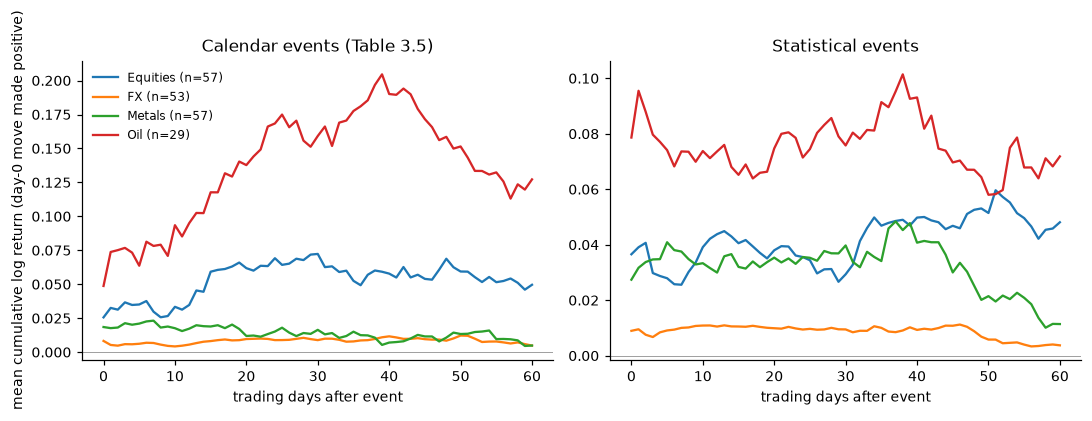

In [16]:
# Event study, equation (3.5.4): cumulative return after each event relative to the pre-event mean
def car_path(r, d, pre, H):
    idx = r.index
    i0 = idx.searchsorted(d)                      # first trading day on or after the event
    if i0 + H >= len(idx) or i0 + pre[0] < 0: return None
    mu = r.iloc[i0 + pre[0]: i0 + pre[1] + 1].mean()
    return (r.iloc[i0: i0 + H + 1] - mu).cumsum().to_numpy()

def event_matrix(dates, label):
    out = []
    for n, rr in rets.items():
        r = rr["r"].dropna()
        for d in dates:
            path = car_path(r, d, P["car_pre"], P["car_horizon"])
            if path is not None:
                out.append(pd.Series(path, name=(label, n, SERIES[n]["asset_class"], pd.Timestamp(d).date())))
    return pd.DataFrame(out)

def overlaps(dates, H):
    d = pd.Series(sorted(pd.to_datetime(dates)))
    gap = d.diff().dt.days
    return set(d[(gap < H * 1.4) | (gap.shift(-1) < H * 1.4)])

cal = event_matrix(events["date"], "calendar")
sta = event_matrix(stat_events["date"], "statistical")
ov = overlaps(events["date"], P["car_horizon"])
print(f"{len(ov)} calendar events overlap with another event within the {P['car_horizon']}-day horizon; they are kept but marked.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, M, title in [(axes[0], cal, "Calendar events (Table 3.5)"), (axes[1], sta, "Statistical events")]:
    if len(M):
        # sign-align paths so that the day-0 move is positive: we study the adjustment, not the direction
        A = M.mul(np.sign(M.iloc[:, 0]).replace(0, 1), axis=0)
        for cls, g in A.groupby(level=2):
            ax.plot(g.mean().values, label=f"{cls} (n={len(g)})")
    ax.axhline(0, color="0.6", lw=0.6); ax.set_title(title); ax.set_xlabel("trading days after event")
axes[0].set_ylabel("mean cumulative log return (day-0 move made positive)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "Figure_3_4_event_paths.png"); plt.show()

## Step 10: Basic statistics and stationarity (Section 3.6.1)

Table 3.7 summarises the daily log returns in both windows: mean and standard deviation (in % per day), skewness, excess kurtosis, the smallest and largest return, the share of returns that are exactly zero (a sign of stale or administered prices), and the Jarque–Bera test of normality. The next cell runs the ADF test (null hypothesis: a unit root) and the KPSS test (null hypothesis: stationarity) on log prices and on returns.

**Reading the output.** Excess kurtosis is zero for a normal distribution, and a Jarque–Bera p-value near zero rejects normality. For the unit-root tests, the expected pattern is that log prices are non-stationary (large ADF p-value, small KPSS p-value) and returns are stationary (small ADF p-value, large KPSS p-value). KPSS p-values are reported only between 0.01 and 0.10 because of how the test's tables are built.

**What it shows.**

- **Not normal.** Returns are far from normal in every series. Excess kurtosis ranges from 7.5 (platinum) to 88 (USD/INR) in the maximal windows, and normality is rejected everywhere.
- **Skewness.** Most series are negatively skewed, meaning large falls are larger than large rises. The exceptions are USD/GBP (+0.48) and USD/INR (+3.0), where the extremes are sudden jumps in the dollar, such as rupee devaluations.
- **Zero returns.** These are rare in most series, but 26 % of USD/INR returns are zero, a sign of the administered exchange rate before 1993. The share falls to 13 % in the common window. Results for the rupee before 1993 should be read with this in mind.
- **Volatility.** Daily volatility is lowest for USD/SGD (0.34 %) and USD/INR (0.46 %) and highest for oil (2.5–2.7 %).
- **Unit roots.** The tests give the expected pattern for every series. USD/GBP is the closest to the line: its log price has an ADF p-value of 0.11, reflecting that sterling has no clear trend over the sample.

In [17]:
def summary(r):
    r = r.dropna()
    jb = stats.jarque_bera(r)
    return dict(N=len(r), mean_pct=100 * r.mean(), sd_pct=100 * r.std(), skew=stats.skew(r),
                excess_kurt=stats.kurtosis(r), min_pct=100 * r.min(), max_pct=100 * r.max(),
                zero_share_pct=100 * (r == 0).mean(), JB=jb.statistic, JB_p=jb.pvalue)

t37 = []
for n, r in rets.items():
    t37.append(dict(series=n, window="maximal", **summary(r["r"])))
    t37.append(dict(series=n, window="common", **summary(common[n])))
table_3_7 = pd.DataFrame(t37).set_index(["series", "window"])
table_3_7.to_csv(OUT_DIR / "tables" / "Table_3_7_summary_statistics.csv")
table_3_7.round(3)

N  mean_pct  sd_pct   skew  excess_kurt  min_pct  max_pct  zero_share_pct           JB  JB_p
series    window                                                                                                   
Gold      maximal  13969     0.034   1.264 -0.125       14.081  -20.316   14.004           1.883   115445.988   0.0
          common    9243     0.022   1.008 -0.340        8.053  -10.392   10.050           0.941    25155.935   0.0
Silver    maximal  13893     0.028   1.976 -0.939       12.890  -32.895   12.832           4.851    98218.013   0.0
          common    9243     0.017   1.878 -1.390       19.469  -32.895   12.832           4.306   148957.141   0.0
Platinum  maximal  13870     0.021   1.684 -0.533        7.497  -22.184   12.014           2.480    33136.671   0.0
          common    9243     0.005   1.488 -0.776        9.546  -20.281   10.163           2.423    36019.888   0.0
S&P 500   maximal  13798     0.031   1.092 -0.957       23.571  -22.900   10.957           0.188   321535.434   0.0
          common    9243     0.030   1.159 -1.211       26.501  -22.900   10.957           0.076   272728.842   0.0
Dow Jones maximal  13798     0.029   1.080 -1.197       32.876  -25.632   10.764           0.275   624669.123   0.0
          common    9243     0.028   1.126 -1.610       40.183  -25.632   10.764           0.130   625849.363   0.0
NASDAQ    maximal  13798     0.040   1.275 -0.328        9.524  -13.149   13.255           0.268    52401.747   0.0
          common    9243     0.039   1.429 -0.287        7.929  -13.149   13.255           0.227    24340.492   0.0
USD/GBP   maximal  13996     0.004   0.589  0.477        8.342   -4.595    9.504           2.115    41112.275   0.0
          common    9243     0.002   0.597  0.681        9.449   -3.131    9.504           1.277    35099.419   0.0
USD/INR   maximal  13331     0.019   0.455  3.008       88.027   -5.518   12.593          25.985  4324242.333   0.0
          common    9243     0.020   0.403  4.972      135.549   -3.490   12.593          12.691  7114215.328   0.0
USD/SGD   maximal  11635    -0.004   0.336 -0.462       10.077   -4.048    2.717           2.510    49640.253   0.0
          common    9243    -0.006   0.338 -0.388       10.221   -4.048    2.717           1.958    40461.857   0.0
WTI       maximal  10154     0.020   2.693 -0.058       24.754  -40.640   42.583           1.389   259261.888   0.0
          common    9243     0.016   2.657 -0.082       27.385  -40.640   42.583           1.093   288823.606   0.0
Brent     maximal   9886     0.017   2.539 -1.686       62.171  -64.370   41.202           1.962  1596819.367   0.0
          common    9243     0.026   2.443 -0.240       23.065  -36.121   41.202           1.893   204976.558   0.0

In [18]:
unit = []
for n, r in rets.items():
    lp = np.log(r["price"][r["price"] > 0])
    x = r["r"].dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # statsmodels version notices and p-value table bounds
        unit.append(dict(series=n,
                         ADF_logprice_p=adfuller(lp, autolag="AIC")[1], KPSS_logprice_p=kpss(lp, nlags="auto")[1],
                         ADF_return_p=adfuller(x, autolag="AIC")[1],   KPSS_return_p=kpss(x, nlags="auto")[1]))
unit_roots = pd.DataFrame(unit).set_index("series")
unit_roots.to_csv(OUT_DIR / "tables" / "unit_root_tests.csv")
print("Expected: log prices non-stationary (ADF p large, KPSS p small); returns stationary (ADF p small, KPSS p large).")
print("KPSS p-values are bounded to [0.01, 0.10] by the test's tables.")
unit_roots.round(3)

Expected: log prices non-stationary (ADF p large, KPSS p small); returns stationary (ADF p small, KPSS p large).
KPSS p-values are bounded to [0.01, 0.10] by the test's tables.


,ADF_logprice_p,KPSS_logprice_p,ADF_return_p,KPSS_return_p
series,,,,
Gold,0.575,0.01,0.0,0.1
Silver,0.710,0.01,0.0,0.1
Platinum,0.411,0.01,0.0,0.1
S&P 500,0.981,0.01,0.0,0.1
Dow Jones,0.970,0.01,0.0,0.1
NASDAQ,0.979,0.01,0.0,0.1
USD/GBP,0.108,0.01,0.0,0.1
USD/INR,0.853,0.01,0.0,0.1
USD/SGD,0.670,0.01,0.0,0.1


## Step 11: Stylised facts and variance ratios (Section 3.6.2)

The first cell checks the standard empirical regularities of financial returns:

- **Heavy tails.** The Hill tail index on the largest 5 % of absolute returns; a lower value means heavier tails. Below about 4, the fourth moment, and so the kurtosis, may not be well defined.
- **Autocorrelation and volatility clustering.** Ljung–Box tests over 10 lags on returns and on absolute returns.
- **Aggregational Gaussianity.** The excess kurtosis of 1-, 5-, 20- and 60-day returns, which should fall towards zero as the horizon grows.

Figure 3.1 shows variance ratios VR(q): the variance of q-day returns divided by q times the variance of daily returns, in the common window. For a random walk the ratio is 1 at every horizon. Below 1 means returns partly reverse (mean reversion); above 1 means they continue (momentum or trend). Open circles mark ratios that differ significantly from 1 under the heteroskedasticity-robust test of Lo and MacKinlay (1988). The model predicts that departures from 1 are concentrated at horizons close to τ.

Figure 3.2 shows the lag-1 autocorrelation over rolling 250-day windows. The grey band is roughly the range expected from noise alone (±2/√250), and the thin vertical lines mark the events in the calendar.

**What it shows.**

- **Tails.** All series are heavy-tailed, with Hill indices between 2.5 and 3.6. For gold, USD/INR, WTI and Brent the index is below 3.
- **Volatility clustering.** This is the strongest regularity in the data. Absolute returns are autocorrelated in every series (Ljung–Box p ≈ 0), with lag-1 autocorrelations of 0.20 to 0.32.
- **Return autocorrelation.** Autocorrelation in returns themselves is small, between −0.07 and +0.04 at lag 1. With samples this long, though, even tiny effects are significant, and the Ljung–Box test rejects for every series except silver.
- **Aggregation.** Kurtosis falls from daily to weekly returns for most series. It stays high at 20 and 60 days for silver, WTI and USD/INR, and at 20 days for gold, where a few extreme episodes, such as the metals bubble of 1980 and the oil collapse of 2020, dominate.
- **Variance ratios (Figure 3.1).**
  - The S&P 500 and Dow Jones show ratios below 1 that keep falling with the horizon: about 0.86 at 5 days, about 0.72 at 60 days and 0.62–0.75 at 250 days. This is significant at short horizons (2–15 days for the S&P 500, 4–6 days for the Dow). It points to short-horizon reversal in large US stocks.
  - NASDAQ stays close to 1.
  - USD/INR rises to 2.0 at 250 days, significant from about one month onwards. This is the trend of a managed, gradually depreciating currency rather than slow adjustment to news.
  - USD/SGD is significantly below 1 at 2–4 days.
  - The other series are not significantly different from 1, even where the point estimate at long horizons is far from it, because the uncertainty there is large.
- **Rolling autocorrelation (Figure 3.2).**
  - The lag-1 autocorrelation has changed a lot over time. In the 1970s and 1980s it was clearly positive for the equity indices: 0.2–0.3 for the S&P 500 and Dow Jones, and up to 0.4–0.6 for NASDAQ. That is typical of index prices that include thinly traded stocks. By around 2000 it had fallen into the noise band.
  - USD/INR shows strongly negative episodes in the 1990s, reaching about −0.5.
  - In 2020 the equity indices dropped to about −0.4, as the COVID crash produced large reversals.
  - The full-sample autocorrelation therefore averages over very different periods, which is an argument for looking at sub-periods.

In [19]:
def hill(r, share=0.05):
    a = np.sort(np.abs(r.dropna().to_numpy()))[::-1]
    k = max(int(share * len(a)), 10)
    return 1 / np.mean(np.log(a[:k] / a[k]))

sf = []
for n, r in rets.items():
    x = r["r"].dropna()
    lb = acorr_ljungbox(x, lags=[10], return_df=True)
    lba = acorr_ljungbox(x.abs(), lags=[10], return_df=True)
    row = dict(series=n, hill_tail_index=hill(x), LB10_r_p=lb["lb_pvalue"].iloc[0], LB10_abs_r_p=lba["lb_pvalue"].iloc[0],
               acf1=x.autocorr(1), acf1_abs=x.abs().autocorr(1))
    for h in [1, 5, 20, 60]:
        agg = x.rolling(h).sum().iloc[h - 1::h]
        row[f"kurt_{h}d"] = stats.kurtosis(agg.dropna())
    sf.append(row)
stylised = pd.DataFrame(sf).set_index("series")
stylised.to_csv(OUT_DIR / "tables" / "stylised_facts.csv")
stylised.round(3)

,hill_tail_index,LB10_r_p,LB10_abs_r_p,acf1,acf1_abs,kurt_1d,kurt_5d,kurt_20d,kurt_60d
series,,,,,,,,,
Gold,2.819,0.002,0.0,-0.010,0.257,14.081,6.882,13.781,2.583
Silver,3.402,0.115,0.0,-0.009,0.241,12.890,4.152,7.204,9.374
Platinum,3.622,0.000,0.0,0.011,0.268,7.497,5.868,4.857,2.757
S&P 500,3.000,0.000,0.0,-0.025,0.254,23.571,4.731,3.749,2.916
Dow Jones,3.058,0.000,0.0,-0.023,0.245,32.876,5.502,3.814,1.880
NASDAQ,2.943,0.000,0.0,0.014,0.324,9.524,5.186,2.510,0.972
USD/GBP,3.514,0.000,0.0,0.042,0.200,8.342,5.637,2.944,2.715
USD/INR,2.530,0.000,0.0,-0.073,0.201,88.027,67.892,19.546,5.952
USD/SGD,3.090,0.000,0.0,-0.063,0.237,10.077,11.219,3.623,3.000


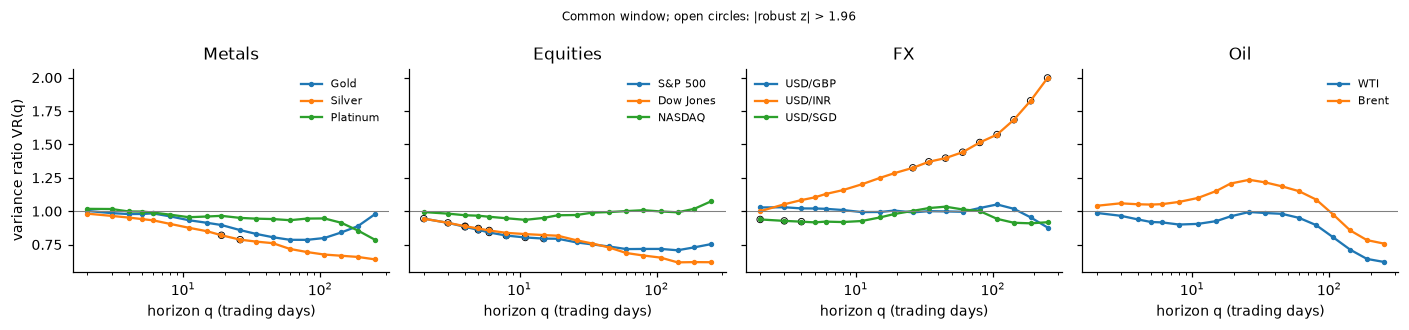

In [20]:
def variance_ratio(r, q):
    # Lo & MacKinlay (1988): overlapping VR with heteroskedasticity-robust z-statistic
    x = r.dropna().to_numpy(); n = len(x); mu = x.mean(); d = x - mu
    var1 = (d @ d) / (n - 1)
    cs = np.concatenate([[0], np.cumsum(x)])
    sq = cs[q:] - cs[:-q] - q * mu
    m = q * (n - q + 1) * (1 - q / n)
    vr = (sq @ sq) / m / var1
    d2 = d ** 2; denom = d2.sum() ** 2
    theta = sum((2 * (q - j) / q) ** 2 * n * (d2[j:] @ d2[:-j]) / denom for j in range(1, q))
    return vr, np.sqrt(n) * (vr - 1) / np.sqrt(theta)

qs = np.unique(np.round(np.logspace(np.log10(2), np.log10(P["vr_max_q"]), 18)).astype(int))
vr_rows = []
for n in rets:
    for q in qs:
        v, z = variance_ratio(common[n], q)
        vr_rows.append(dict(series=n, q=q, VR=v, z_robust=z))
vr = pd.DataFrame(vr_rows)
vr.to_csv(OUT_DIR / "tables" / "variance_ratios_common_window.csv", index=False)

cls_order = list(dict.fromkeys(SERIES[n]["asset_class"] for n in rets))
fig, axes = plt.subplots(1, len(cls_order), figsize=(3.2 * len(cls_order), 3), sharey=True)
for ax, cls in zip(np.atleast_1d(axes), cls_order):
    for n in [s for s in rets if SERIES[s]["asset_class"] == cls]:
        g = vr[vr.series == n]
        ax.semilogx(g.q, g.VR, marker="o", ms=2.5, label=n)
        sig = g[np.abs(g.z_robust) > 1.96]
        ax.scatter(sig.q, sig.VR, s=18, facecolors="none", edgecolors="k", lw=0.6)
    ax.axhline(1, color="0.5", lw=0.7); ax.set_title(cls); ax.set_xlabel("horizon q (trading days)")
    ax.legend(frameon=False, fontsize=7)
np.atleast_1d(axes)[0].set_ylabel("variance ratio VR(q)")
fig.suptitle("Common window; open circles: |robust z| > 1.96", fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "Figure_3_1_variance_ratios.png"); plt.show()

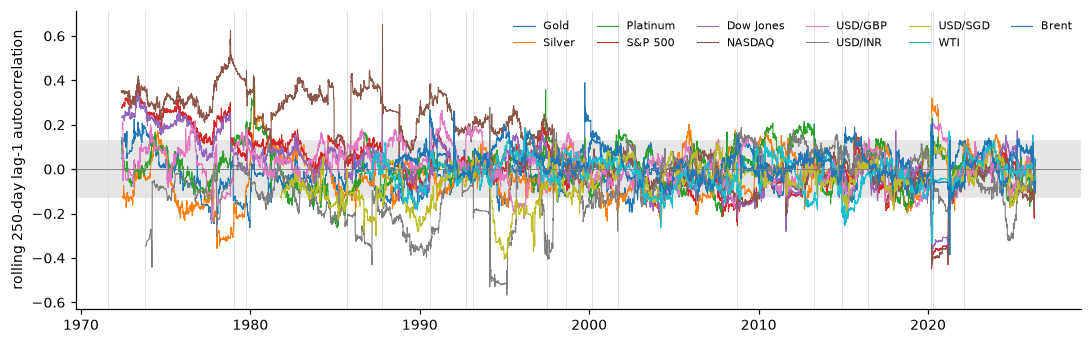

In [21]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for n, r in rets.items():
    x = r["r"]
    ax.plot(x.rolling(250, min_periods=200).corr(x.shift(1)), lw=0.7, label=n)
ax.axhline(0, color="0.5", lw=0.6)
ax.axhspan(-2 / np.sqrt(250), 2 / np.sqrt(250), color="0.9", zorder=0)
for d in events["date"]: ax.axvline(d, color="0.85", lw=0.5, zorder=0)
ax.set_ylabel("rolling 250-day lag-1 autocorrelation"); ax.legend(ncol=6, frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "Figure_3_2_rolling_autocorrelation.png"); plt.show()

## Step 12: Lead–lag and spectral properties (Sections 3.6.3, 3.4.4)

This step produces four outputs.

**Figure 3.3** is the cross-correlation between a proxy today and returns ℓ days later, for ℓ from −20 to 20. Signed proxies are correlated with returns and unsigned proxies with absolute returns. Positive lags mean the proxy comes first. The shaded band is roughly the 95 % range for noise, and lag 0 is greyed out because the link there is mechanical.

**Figure 3.5** has three panels:

- (a) The return spectrum divided by that of white noise. A random walk gives a flat line at 1; values above 1 at low frequencies indicate persistence, and values below 1 indicate mean reversion. The period is one over the frequency, so 0.01 corresponds to 100 trading days and 0.1 to 10 days.
- (b) and (c) The gain and phase of the cross-spectrum between the proxy and later returns, built from lags 1–60 only. The model predicts a bend in the gain and a shift in the phase around the frequency 1/τ. What matters is a change in shape there, not the levels.

**The Lomb–Scargle check** compares the spectrum computed in calendar time with the one in trading time. If they agree, measuring time in trading days does not distort the results.

**Cross-asset correlations** are computed at lags −1, 0 and +1 day, and with two-day returns. Markets close at different times of day, so an apparent one-day lead between two assets may simply reflect when their prices are recorded. Two-day returns remove most of that effect.

**What it shows.**

- **Figure 3.3.**
  - The signed proxies do not predict the direction of later returns. At lags 1–5 every correlation is below 0.03 in absolute value, inside or at the edge of the noise band (about ±0.017). The largest values are USD/GBP (0.032 at lag 1), Brent (0.027) and NASDAQ (0.026).
  - The unsigned proxies tell a very different story. Today's volatility is strongly correlated with the size of returns in the following days: 0.26 to 0.50 one day ahead, and still 0.16 to 0.33 twenty days ahead.
  - Information arrival, as measured here, therefore affects how large later moves are for several weeks, but not which way they go. This slow decay is where the relaxation-time signal should show up in later chapters.
- **Figure 3.5a.** At periods longer than about 100 trading days, the S&P 500 and Dow Jones lie below 1 (about 0.8), matching the mean reversion seen in the variance ratios. NASDAQ, USD/GBP and USD/SGD lie above 1 (about 1.25–1.35), indicating persistence. At shorter periods all series fluctuate around 1.
- **Figure 3.5b–c.**
  - The gain is noisy and shows no clear bend at any single frequency, so no τ can be read directly from these raw daily cross-spectra; that is the job of the estimation in later chapters.
  - The phase at low frequencies differs widely between series: about +160° for the S&P 500 and Dow Jones, around −15° for most other series including NASDAQ, and about −155° for WTI. With no common pattern across series, the phase cannot be interpreted yet.
- **Lomb–Scargle.** The calendar-time periodogram is unsmoothed and therefore very noisy, but it scatters around the trading-time Welch spectrum with no systematic difference for any series. Working in trading time does not appear to distort the spectra.
- **Cross-asset correlations.**
  - Same-day correlations are high within groups: S&P 500 and Dow Jones 0.94, WTI and Brent 0.63, the three metals 0.5–0.7. A stronger dollar goes with lower metal prices (about −0.2 to −0.25).
  - The largest one-day lead is WTI today with Brent tomorrow (0.26). Brent is assessed in London, earlier in the day than WTI in the United States, so part of each WTI move only shows up in Brent the next day. The two-day correlation rises to 0.74, which confirms that this lead is mostly about recording times.
  - Similar one-day leads appear from sterling, the Singapore dollar and the equities to the rupee, whose market closes before London and New York.
  - One-day leads between assets should therefore not be read as slow information flow without allowing for recording times.

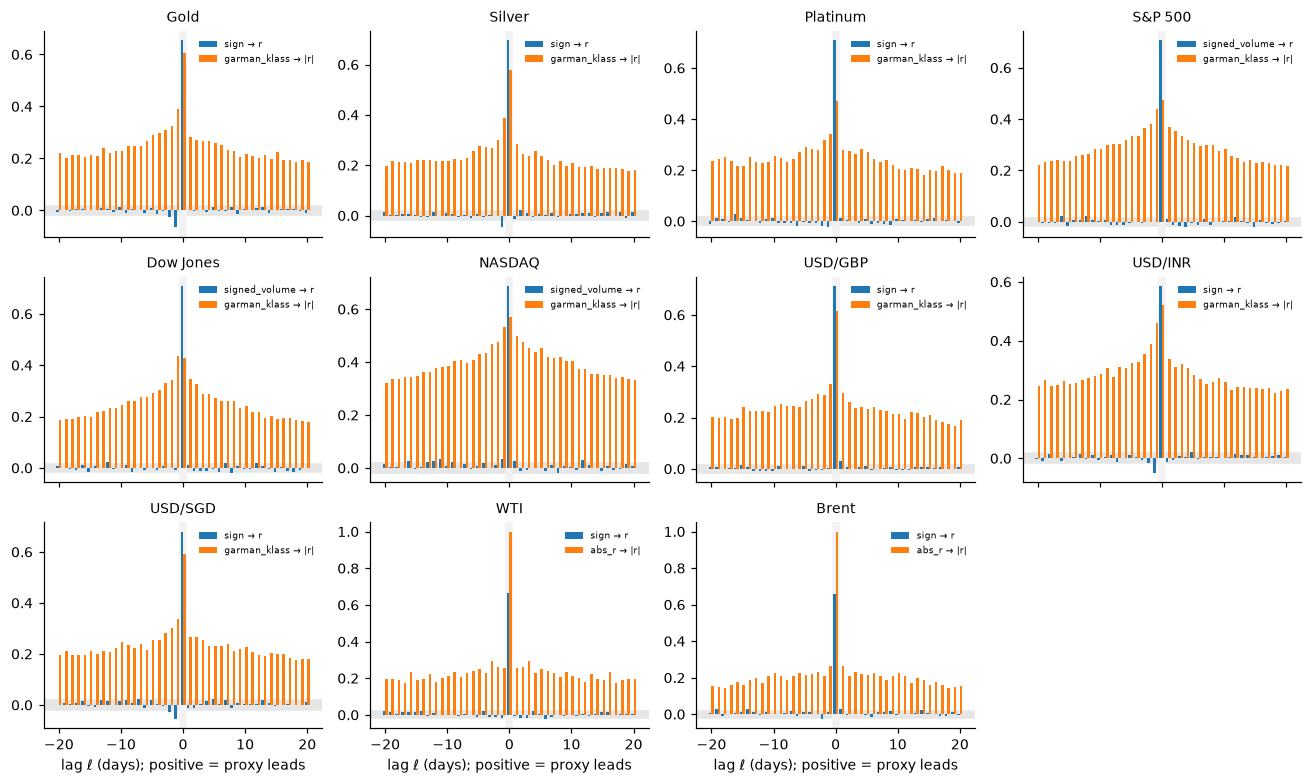

In [22]:
def ccf(x, y, L):
    j = pd.concat([x, y], axis=1, keys=["x", "y"]).dropna()
    return pd.Series({l: j["x"].corr(j["y"].shift(-l)) for l in range(-L, L + 1)}), len(j)

def main_proxy(n):
    px = proxies[n]
    signed = "signed_volume" if "signed_volume" in px else "sign"
    unsigned = "garman_klass" if "garman_klass" in px else ("parkinson" if "parkinson" in px else "abs_r")
    return signed, unsigned

L = P["ccf_max_lag"]; names = list(rets)
ncol = 4; nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 2.4 * nrow), sharex=True)
ccf_out = []
for ax, n in zip(axes.flat, names):
    s, u = main_proxy(n)
    c1, N = ccf(proxies[n][s], rets[n]["r"], L)
    c2, _ = ccf(proxies[n][u], rets[n]["r"].abs(), L)
    ax.bar(c1.index - 0.2, c1.values, width=0.4, label=f"{s} → r")
    ax.bar(c2.index + 0.2, c2.values, width=0.4, label=f"{u} → |r|")
    ax.axhspan(-1.96 / np.sqrt(N), 1.96 / np.sqrt(N), color="0.9", zorder=0)
    ax.axvspan(-0.5, 0.5, color="0.95", zorder=0)
    ax.set_title(n, fontsize=9); ax.legend(frameon=False, fontsize=6)
    ccf_out.append(pd.DataFrame({"series": n, "lag": c1.index, f"signed:{s}": c1.values, f"unsigned:{u}": c2.values}))
for ax in axes.flat[len(names):]: ax.axis("off")
for ax in axes[-1]: ax.set_xlabel("lag ℓ (days); positive = proxy leads")
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "Figure_3_3_cross_correlations.png"); plt.show()
pd.concat(ccf_out).to_csv(OUT_DIR / "tables" / "cross_correlations.csv", index=False)

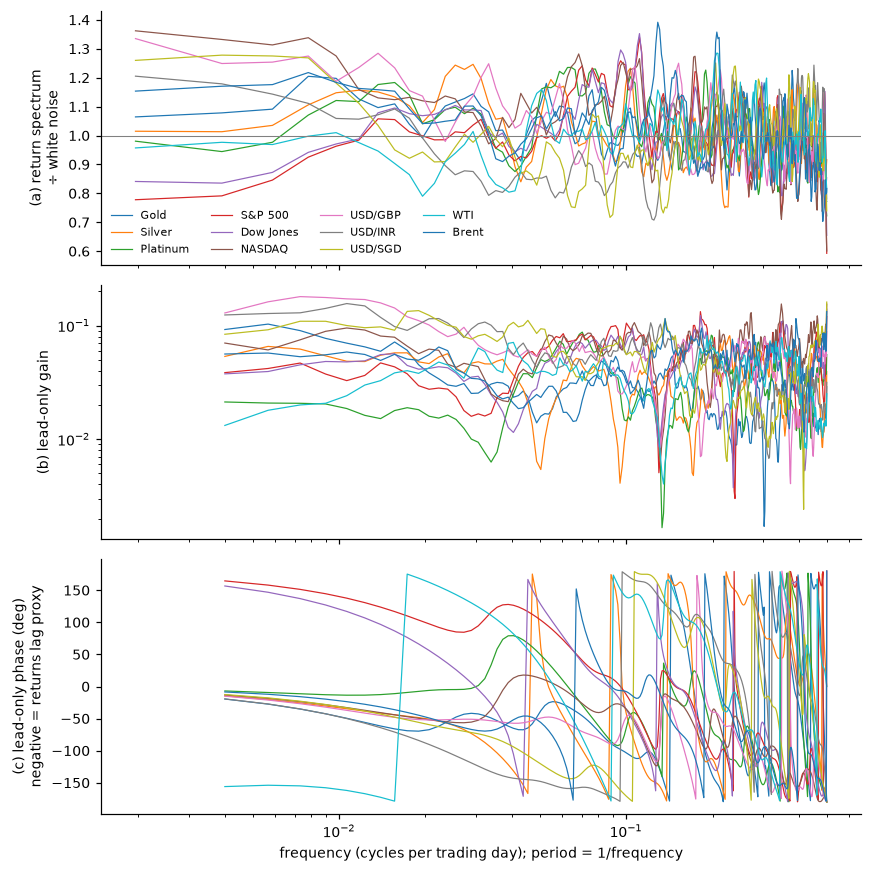

In [23]:
# Figure 3.5. The daily proxies are built from the same day's return, so the ordinary cross-spectrum is dominated
# by their mechanical lag-0 link (coherence ~0.5 at every frequency). We therefore use the *lead-only* cross-spectrum:
# the Fourier transform of the cross-covariance between the proxy today and returns l = 1..L_SPEC days later
# (Blackman–Tukey estimate with a Parzen lag window). Panel (a) shows the return spectrum itself relative to white noise.
L_SPEC = 60
f_grid = np.linspace(1 / 250, 0.5, 300)                     # cycles per trading day (periods 2–250 days)

def parzen(L):
    u = np.arange(1, L + 1) / (L + 1)
    return np.where(u <= 0.5, 1 - 6 * u**2 + 6 * u**3, 2 * (1 - u)**3)

def lead_only_spectrum(x, y, L, f):
    x = (x - x.mean()) / x.std(); y = (y - y.mean()) / y.std()
    n = len(x); lags = np.arange(1, L + 1)
    g = np.array([np.dot(x[:-l], y[l:]) / n for l in lags])        # cov(x_t, r_{t+l})
    w = parzen(L)
    return (w * g) @ np.exp(-2j * np.pi * np.outer(lags, f)), g

fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
spec_rows = []
for n in names:
    s, _ = main_proxy(n)
    j = pd.concat([proxies[n][s], rets[n]["z"]], axis=1, keys=["x", "r"]).dropna()
    x, y = j["x"].to_numpy(float), j["r"].to_numpy(float)
    nper = min(P["welch_nperseg"], len(y) // 8)
    fw, Syy = signal.welch(y - y.mean(), fs=1.0, nperseg=nper)
    _, Sxx = signal.welch(x - x.mean(), fs=1.0, nperseg=nper)
    rel = Syy / Syy[1:].mean()                                   # 1 = white noise (random walk)
    Sxx_g = np.interp(f_grid, fw, Sxx / Sxx[1:].mean())          # normalised so that white noise = 1
    Sl, g = lead_only_spectrum(x, y, L_SPEC, f_grid)
    gain = np.abs(Sl) / Sxx_g; phase = np.degrees(np.angle(Sl))
    axes[0].semilogx(fw[1:], pd.Series(rel[1:]).rolling(5, center=True, min_periods=1).mean(), lw=0.8, label=n)
    axes[1].loglog(f_grid, gain, lw=0.8); axes[2].semilogx(f_grid, phase, lw=0.8)
    spec_rows.append(pd.DataFrame({"series": n, "proxy": s, "freq_cycles_per_day": f_grid, "period_days": 1 / f_grid,
                                   "lead_gain": gain, "lead_phase_deg": phase}))
axes[0].axhline(1, color="0.5", lw=0.7)
axes[0].set_ylabel("(a) return spectrum\n÷ white noise"); axes[1].set_ylabel("(b) lead-only gain")
axes[2].set_ylabel("(c) lead-only phase (deg)\nnegative = returns lag proxy")
axes[2].set_xlabel("frequency (cycles per trading day); period = 1/frequency")
axes[0].legend(ncol=4, frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "Figure_3_5_spectra_gain_phase.png"); plt.show()
pd.concat(spec_rows).to_csv(OUT_DIR / "tables" / "lead_only_cross_spectra.csv", index=False)

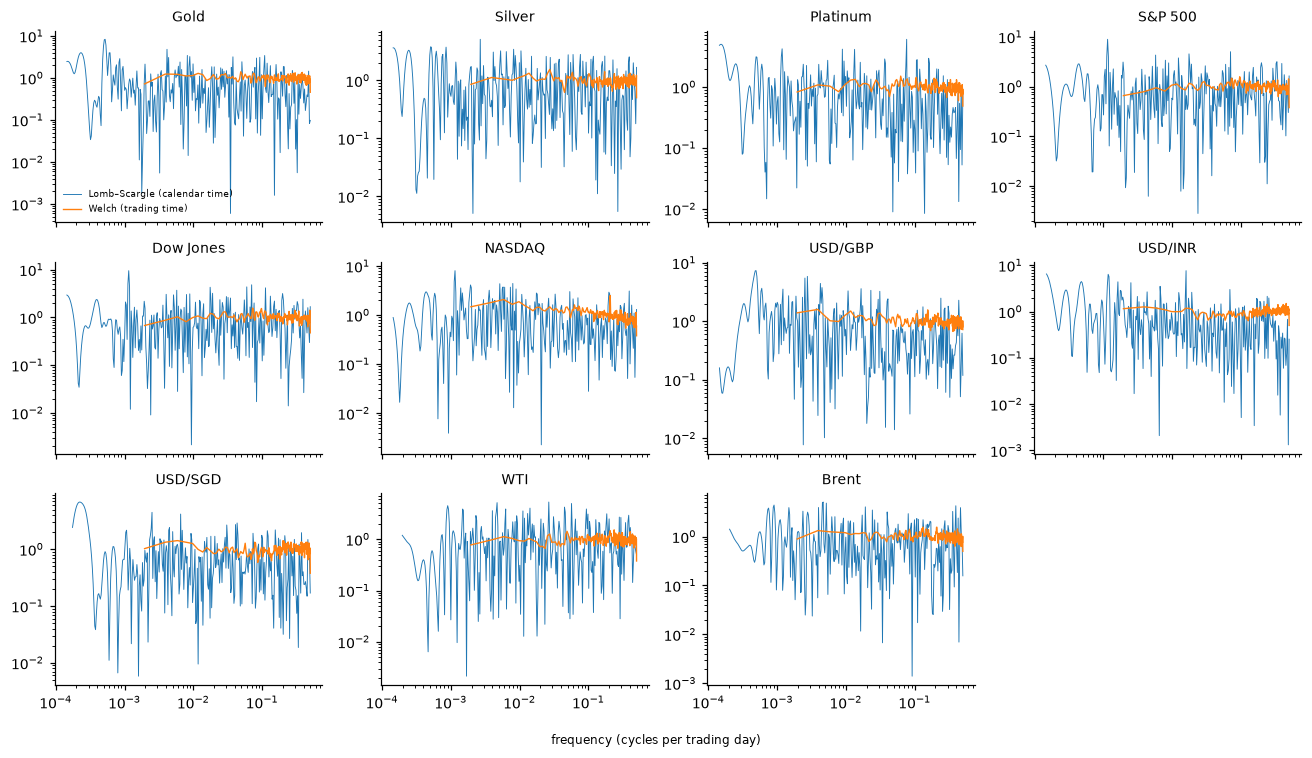

In [24]:
# Lomb–Scargle (calendar time) versus Welch (trading time) for returns: a check on the irregular calendar
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 2.3 * nrow), sharex=True)
for ax, n in zip(axes.flat, names):
    r = rets[n]["z"].dropna()
    tcal = (r.index - r.index[0]).days.to_numpy().astype(float)
    y = r.to_numpy() - r.mean()
    f_cal = np.logspace(np.log10(2 / tcal[-1]), np.log10(0.5 * 252 / 365), 300)    # cycles per calendar day
    ls = signal.lombscargle(tcal, y, 2 * np.pi * f_cal, normalize=True)
    f_w, S = signal.welch(y, fs=1.0, nperseg=min(P["welch_nperseg"], len(y) // 8))
    ax.loglog(f_cal * 365 / 252, ls / ls.mean(), lw=0.6, label="Lomb–Scargle (calendar time)")
    ax.loglog(f_w[1:], S[1:] / S[1:].mean(), lw=0.9, label="Welch (trading time)")
    ax.set_title(n, fontsize=9)
for ax in axes.flat[len(names):]: ax.axis("off")
axes.flat[0].legend(frameon=False, fontsize=6)
fig.supxlabel("frequency (cycles per trading day)", fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "lomb_scargle_check.png"); plt.show()

In [25]:
# Cross-asset correlations at lags -1, 0, +1 day (common window) and with 2-day returns (Section 3.4.4)
def lag_corr(df, lag):
    return pd.DataFrame({a: {b: df[a].corr(df[b].shift(-lag)) for b in df} for a in df}).T  # row a leads column b by `lag`

zc_common = pd.concat({n: rets[n]["z"] for n in rets}, axis=1, sort=True).loc[common.index]
tables = {f"lag{l:+d}": lag_corr(zc_common, l) for l in (-1, 0, 1)}
two_day = zc_common.rolling(2).sum().iloc[1::2]
tables["2day_lag0"] = lag_corr(two_day, 0)
for k, t in tables.items():
    t.to_csv(OUT_DIR / "tables" / f"cross_asset_corr_{k}.csv")
print("Row leads column by one day (lag +1). Large values here may reflect recording-time order (Section 3.2.3):")
tables["lag+1"].round(2)

Row leads column by one day (lag +1). Large values here may reflect recording-time order (Section 3.2.3):


,Gold,Silver,Platinum,S&P 500,Dow Jones,NASDAQ,USD/GBP,USD/INR,USD/SGD,WTI,Brent
Gold,0.02,0.00,0.07,0.00,0.00,-0.00,-0.02,-0.08,-0.04,-0.02,0.02
Silver,0.01,0.01,0.08,-0.00,-0.00,-0.00,-0.02,-0.08,-0.03,-0.01,0.03
Platinum,0.02,0.01,0.04,0.00,0.01,0.00,-0.01,-0.07,-0.02,0.01,0.04
S&P 500,0.03,0.06,0.06,-0.01,0.00,0.04,-0.02,-0.10,0.00,0.03,0.05
Dow Jones,0.03,0.05,0.05,-0.02,-0.00,0.02,-0.02,-0.09,0.01,0.02,0.04
NASDAQ,0.02,0.06,0.05,-0.00,0.00,0.05,-0.02,-0.09,-0.00,0.02,0.04
USD/GBP,-0.01,-0.00,-0.04,-0.01,-0.01,-0.00,0.02,0.11,0.05,-0.01,-0.03
USD/INR,0.01,0.01,0.01,-0.00,-0.01,-0.00,0.01,-0.03,-0.01,-0.00,-0.01
USD/SGD,-0.02,-0.01,-0.04,-0.01,-0.02,-0.00,0.02,0.11,-0.03,-0.02,-0.03
WTI,0.02,0.02,0.05,0.00,0.00,0.00,0.00,-0.01,-0.00,0.01,0.26


## Step 13: Save the processed data (Section 3.3.2)

The cleaned returns, standardised returns and proxies are saved, together with a JSON record of all settings used in the run, so that Chapter 4 starts from exactly this version of the data.

**Where the outputs go in Chapter 3:**

| In the chapter | File in `output/tables/` |
|---|---|
| Table 3.1 start dates | `Table_3_3_sources_and_fields.csv` (column `first_date`) |
| Table 3.2 | `Table_3_2_windows.csv`, `Table_3_2_thesis_format.csv` |
| Table 3.3 | `Table_3_3_sources_and_fields.csv` |
| Table 3.4 | `Table_3_4_extreme_returns.csv` |
| Table 3.6 availability check | `Table_3_6_proxy_availability.csv` |
| Table 3.7 | `Table_3_7_summary_statistics.csv` |
| Table A.1 (appendix) | `calendar_completeness.csv` |
| Corrections log | `corrections_log.csv` |
| Section 3.2.2 sample sizes | `Table_3_2_windows.csv` |
| Figures 3.1–3.5 | `output/figures/` |
| Data behind Figure 3.5 | `lead_only_cross_spectra.csv` |

In [26]:
long = []
for n, r in rets.items():
    d = r[["price", "r", "r_simple", "gap_days", "z", "sigma_ewma", "holdout"]].join(proxies[n].drop(columns=["abs_r", "ewma_vol"]), how="left")
    d.insert(0, "series", n); long.append(d)
pd.concat(long).to_csv(OUT_DIR / "processed" / "returns_and_proxies_long.csv")
common.to_csv(OUT_DIR / "processed" / "common_window_returns.csv")

settings = dict(run_at=dt.datetime.now().isoformat(timespec="seconds"), demo=DEMO, start_date=START_DATE,
                end_date=END_DATE, common_start=str(COMMON_START.date()), series=SERIES,
                second_sources=SECOND_SOURCES, parameters=P, confirmed_errors=CONFIRMED_ERRORS,
                n_calendar_events=len(events), n_statistical_events=len(stat_events))
(OUT_DIR / "processed" / "run_settings.json").write_text(json.dumps(settings, indent=2, default=str))
print("Saved:"); [print(" ", p) for p in sorted(OUT_DIR.rglob("*")) if p.is_file()]
if DEMO: print("\nDEMO RUN – these outputs come from simulated data and must not be used in the thesis.")

Saved:
  output\figures\Figure_3_1_variance_ratios.png
  output\figures\Figure_3_2_rolling_autocorrelation.png
  output\figures\Figure_3_3_cross_correlations.png
  output\figures\Figure_3_4_event_paths.png
  output\figures\Figure_3_5_spectra_gain_phase.png
  output\figures\lomb_scargle_check.png
  output\processed\common_window_returns.csv
  output\processed\returns_and_proxies_long.csv
  output\processed\run_settings.json
  output\tables\administered_period_moves.csv
  output\tables\calendar_completeness.csv
  output\tables\corrections_log.csv
  output\tables\cross_asset_corr_2day_lag0.csv
  output\tables\cross_asset_corr_lag+0.csv
  output\tables\cross_asset_corr_lag+1.csv
  output\tables\cross_asset_corr_lag-1.csv
  output\tables\cross_correlations.csv
  output\tables\integrity_checks.csv
  output\tables\lead_only_cross_spectra.csv
  output\tables\missing_days_fx_metals.csv
  output\tables\observations_outside_calendar.csv
  output\tables\review_candidates.csv
  output\tables\statis

## Summary: what the data show so far

**The data are in good shape.** No file has dates out of order, duplicated dates or inconsistent price ranges. The equity indices are complete against the NYSE calendar; exchange rates and metals miss at most a few per cent of weekdays, mostly holidays, and never more than four trading days in a row. One bad record, a Saturday price in the Dow Jones file, was removed. The negative WTI price of April 2020 is genuine and is handled by excluding the two log returns around it.

**Returns behave like typical financial returns.** They are heavy-tailed and clearly non-normal, and volatility clusters strongly in every series. Log prices are non-stationary and returns stationary.

**Direction is hard to predict; size is not.** Signed proxies hardly predict later returns. Volatility today, however, is strongly linked to the size of returns over the following weeks, and this slow decay is where the relaxation dynamics should appear.

**There are signs of slow adjustment and of reversal.** US large-cap equities show significant short-horizon mean reversion. After major events, oil and equities keep moving in the direction of the shock for several weeks, while metals and exchange rates adjust mostly on the day. The event evidence rests on few events, and for oil largely on the COVID-19 episode, so it is suggestive only.

**Time and recording matter.** Autocorrelation has changed a lot since the 1970s, so full-sample results mix different periods. Apparent one-day leads between assets, such as WTI to Brent, are mostly explained by different recording times. The common window can resolve relaxation times up to about 92 trading days; slower adjustment can only be studied in the longer single-series samples.

**Still to do before the chapter is final:**

- Review the 218 flagged returns on the review list in Step 6 and record any confirmed errors.
- Describe the unmatched statistical events (Step 9) in the chapter, rather than adding them to the event calendar.